In [1]:
import gc
import glob
import itertools
import json
import os
import re
import unicodedata
import warnings
from datetime import datetime, timezone
from pathlib import Path
from xml.etree import ElementTree as ET

from IPython.display import display
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import seaborn as sns
import yaml

try:
    from pypdf import PdfReader
except ModuleNotFoundError:
    PdfReader = None

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 5)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 40)

BASE = Path('.')
print('Рабочая папка:', BASE.resolve())

Рабочая папка: /Users/macbook/Desktop/Masters_degree/3_semester/Data Science/Catch_the_spies


## 1. BoardingData.csv


In [2]:
boarding = pd.read_csv(BASE / 'BoardingData.csv', sep=';')

print('Размер датасета:', boarding.shape)
print('\nТипы данных:')
print(boarding.dtypes)
print('\nПропуски:')
print(boarding.isnull().sum())
print('\nЗначения "Not presented":')
for col in boarding.columns:
    n = (boarding[col] == 'Not presented').sum()
    if n > 0:
        print(f'  {col}: {n}')

Размер датасета: (155147, 14)

Типы данных:
PassengerFirstName     object
PassengerSecondName    object
PassengerLastName      object
PassengerSex           object
PassengerBirthDate     object
PassengerDocument      object
BookingCode            object
TicketNumber           object
Baggage                object
FlightDate             object
FlightTime             object
FlightNumber           object
CodeShare              object
Destination            object
dtype: object

Пропуски:
PassengerFirstName         0
PassengerSecondName        0
PassengerLastName          0
PassengerSex               0
PassengerBirthDate         0
PassengerDocument          0
BookingCode                0
TicketNumber               0
Baggage                38932
FlightDate                 0
FlightTime                 0
FlightNumber               0
CodeShare                  0
Destination                0
dtype: int64

Значения "Not presented":
  BookingCode: 77761
  TicketNumber: 77800


In [3]:
boarding.head(10)

,PassengerFirstName,PassengerSecondName,PassengerLastName,PassengerSex,PassengerBirthDate,PassengerDocument,BookingCode,TicketNumber,Baggage,FlightDate,FlightTime,FlightNumber,CodeShare,Destination
0,SAVELII,VIKTOROVICH,RUSANOV,Male,03/10/1983,2879 096860,FRNINO,6625956945991971,Transit,2017-03-22,06:05,SU1369,Own,Moscow
1,LEV,MARKOVICH,ISAEV,Male,12/13/1975,1788 173211,Not presented,1643715499224676,Registered,2017-03-18,22:10,SU1180,Own,Volgograd
2,NIKOLAI,I.,NIKOLSKII,Male,12/26/1990,4396 926588,VWNYGF,6247422701565929,Transit,2017-03-18,22:10,SU1180,Own,Volgograd
3,ANATOLII,PETROVICH,SHILOV,Male,05/24/1997,2595 919752,WQFFUE,Not presented,Registered,2017-03-18,22:10,SU1180,Own,Volgograd
4,MIROSLAVA,VIACHESLAVOVNA,SEMENOVA,Female,01/31/1976,6775 516990,Not presented,Not presented,Registered,2017-03-12,11:45,SU6284,Own,Moscow
5,ARTEM,EDUARDOVICH,KAPUSTIN,Male,10/24/1982,0058 142289,JJADFB,7467749130398378,Transit,2017-03-12,11:45,SU6284,Own,Moscow
6,ZARINA,E.,TITOVA,Female,12/22/2000,6600 251370,Not presented,5954073786122008,NaN,2017-07-29,14:15,SU1281,Own,Moscow
7,SAMIR,GORDEEVICH,BARSUKOV,Male,02/21/1995,0078 271703,WGKZTB,2264717979478322,Registered,2017-07-29,14:15,SU1281,Own,Moscow
8,RAMIL,E.,ROZHKOV,Male,02/02/1980,0595 142701,POFVPI,Not presented,Registered,2017-04-07,00:15,SU1482,Own,Krasnoyarsk
9,ALBINA,V.,KONSTANTINOVA,Female,07/04/1997,0916 040520,Not presented,1678047813210634,Registered,2017-04-07,00:15,SU1482,Own,Krasnoyarsk


In [4]:
boarding.replace('Not presented', np.nan, inplace=True)
boarding['PassengerBirthDate'] = pd.to_datetime(boarding['PassengerBirthDate'], format='%m/%d/%Y', errors='coerce')
boarding['FlightDate']         = pd.to_datetime(boarding['FlightDate'], errors='coerce')

# внешний ключ по имени
boarding['full_name_key'] = (
    boarding['PassengerFirstName'].fillna('') + ' ' +
    boarding['PassengerSecondName'].fillna('') + ' ' +
    boarding['PassengerLastName'].fillna('')
).str.strip()

print(boarding.describe(include='all').T)

                      count unique                 top    freq  \
PassengerFirstName   155147    200               NAZAR     932   
PassengerSecondName  155147    214                  A.   11119   
PassengerLastName    155147   1006            CHERNYKH     290   
PassengerSex         155147      2              Female   77863   
PassengerBirthDate   155147    NaN                 NaN     NaN   
PassengerDocument    155147  73263         1548 113497      16   
BookingCode           77386  77373              WSSVOO       2   
TicketNumber          77347  77347    6625956945991971       1   
Baggage              116215      3          Registered   38957   
FlightDate           155147    NaN                 NaN     NaN   
FlightTime           155147    206               06:05    3221   
FlightNumber         155147    385              SU4606    2909   
CodeShare            155147      2                 Own  146373   
Destination          155147     48              Moscow   88022   
full_name_

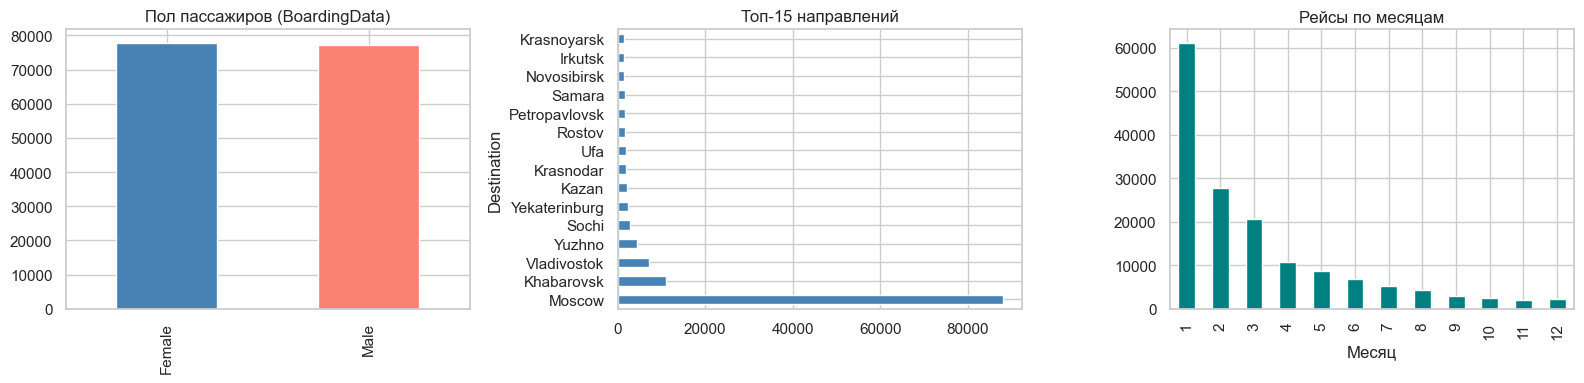

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# пол
boarding['PassengerSex'].value_counts().plot(kind='bar', ax=axes[0], color=['steelblue','salmon'])
axes[0].set_title('Пол пассажиров (BoardingData)')
axes[0].set_xlabel('')

# направление
boarding['Destination'].value_counts().head(15).plot(kind='barh', ax=axes[1], color='steelblue')
axes[1].set_title('Топ-15 направлений')

# месяц
boarding['FlightDate'].dt.month.value_counts().sort_index().plot(kind='bar', ax=axes[2], color='teal')
axes[2].set_title('Рейсы по месяцам')
axes[2].set_xlabel('Месяц')

plt.tight_layout()
plt.show()

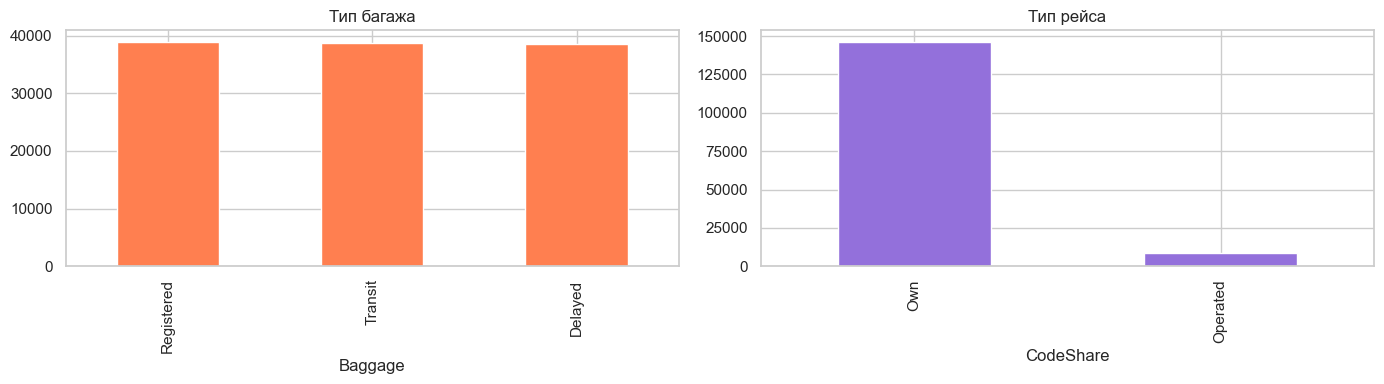

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# тип багажа
boarding['Baggage'].value_counts().plot(kind='bar', ax=axes[0], color='coral')
axes[0].set_title('Тип багажа')

# тип рейса
boarding['CodeShare'].value_counts().plot(kind='bar', ax=axes[1], color='mediumpurple')
axes[1].set_title('Тип рейса')

plt.tight_layout()
plt.show()

## 2. Sirena-export-fixed.tab


In [7]:
colspecs = [
    (0,   60),  # PaxName
    (60,  72),  # PaxBirthDate
    (72,  84),  # DepartDate
    (84,  96),  # DepartTime
    (96,  108), # ArrivalDate
    (108, 120), # ArrivalTime
    (120, 126), # FlightCode
    (126, 132), # CodeShare
    (132, 138), # From
    (138, 144), # Dest
    (144, 150), # Code (PNR)
    (150, 168), # e-Ticket
    (168, 180), # TravelDoc
    (180, 186), # Seat
    (186, 192), # Meal
    (192, 198), # TrvCls
    (198, 204), # Fare
    (204, 216), # Baggage
    (216, 276), # PaxAdditionalInfo
    (276, 336), # AgentInfo
]
col_names = [
    'PaxName','PaxBirthDate','DepartDate','DepartTime','ArrivalDate','ArrivalTime',
    'FlightCode','CodeShare','From','Dest','Code','e-Ticket','TravelDoc','Seat','Meal',
    'TrvCls','Fare','Baggage','PaxAdditionalInfo','AgentInfo'
]

sirena = pd.read_fwf(
    BASE / 'Sirena-export-fixed.tab',
    colspecs=colspecs, names=col_names, skiprows=1
)
# чистим от пробелов
for col in sirena.select_dtypes(include='object').columns:
    sirena[col] = sirena[col].str.strip()

sirena.replace('N/A', np.nan, inplace=True)

print('Форма:', sirena.shape)
print('\nКолонки:', list(sirena.columns))
print('\nТипы:\n', sirena.dtypes)

Форма: (155757, 20)

Колонки: ['PaxName', 'PaxBirthDate', 'DepartDate', 'DepartTime', 'ArrivalDate', 'ArrivalTime', 'FlightCode', 'CodeShare', 'From', 'Dest', 'Code', 'e-Ticket', 'TravelDoc', 'Seat', 'Meal', 'TrvCls', 'Fare', 'Baggage', 'PaxAdditionalInfo', 'AgentInfo']

Типы:
 PaxName               object
PaxBirthDate          object
DepartDate            object
DepartTime            object
ArrivalDate           object
ArrivalTime           object
FlightCode            object
CodeShare             object
From                  object
Dest                  object
Code                  object
e-Ticket               int64
TravelDoc             object
Seat                 float64
Meal                  object
TrvCls                object
Fare                  object
Baggage               object
PaxAdditionalInfo     object
AgentInfo             object
dtype: object


In [8]:
sirena.head(10)

,PaxName,PaxBirthDate,DepartDate,DepartTime,ArrivalDate,ArrivalTime,FlightCode,CodeShare,From,Dest,Code,e-Ticket,TravelDoc,Seat,Meal,TrvCls,Fare,Baggage,PaxAdditionalInfo,AgentInfo
0,ОЗЕРОВ ИЛЬДАР ДАНИИЛОВИЧ,1999-05-15,2017-05-30,00:05,2017-05-30,08:05,SU1306,NO,SVO,OVB,ZBQSPY,7360415302044672,9375 053270,NaN,NaN,J,JGRPGN,0PC,S FF#SU 38116280,Go2See
1,КОЛОСОВ САМИР ТАМЕРЛАНОВИЧ,NaN,2017-12-27,02:15,2017-12-27,04:40,SU1323,NO,MMK,SVO,MHPBBX,7398421117936516,2244 645520,NaN,KSML,Y,YRSTUQ,NaN,9 FF#FB 284903754,NaN
2,ИГНАТОВА СНЕЖАНА КОНСТАНТИНОВНА,NaN,2017-09-19,06:40,2017-09-19,07:45,SU1481,NO,KJA,SVO,REDLVB,5174973140468001,8115 961316,NaN,NaN,Y,YSTNJL,NaN,F,KupiBilet
3,ЖАРОВ ПЛАТОН АЛЬБЕРТОВИЧ,1999-05-02,2017-03-18,22:10,2017-03-19,01:05,SU1180,NO,SVO,VOG,NSJNGQ,5274206497242737,98 6865148,NaN,NaN,J,JFLXLS,0PC,# FF#FB 884556993,Travelgenio
4,НИКОЛЬСКИЙ НИКОЛАЙ ИГОРЕВИЧ,1990-12-26,2017-03-18,22:10,2017-03-19,01:05,SU1180,NO,SVO,VOG,VWNYGF,6247422701565929,4396 926588,NaN,NaN,Y,YFLXPG,NaN,FF#SU 183142068,OZON.travel
5,ГЛУШКОВ КОНСТАНТИН ИЛЬИЧ,NaN,2017-03-12,11:45,2017-03-12,12:25,SU6284,NO,UUS,SVO,QSDXJY,5874178506968181,4788 422492,NaN,NaN,Y,YGRPPN,0PC,8 FF#FB 553284496,KupiBilet
6,КАПУСТИН АРТЁМ ЭДУАРДОВИЧ,1982-10-24,2017-03-12,11:45,2017-03-12,12:25,SU6284,NO,UUS,SVO,JJADFB,7467749130398378,0058 142289,NaN,VLML,Y,YFLXNM,2PC,F,KupiBilet
7,ЕРШОВА ЛЮБОВЬ ЗАХАРОВНА,NaN,2017-03-12,11:45,2017-03-12,12:25,SU6284,NO,UUS,SVO,UMTOZM,2183161939566868,0776 380126,NaN,NaN,Y,YGRPYX,0PC,#,Aeroflot
8,ТИТОВА ЗАРИНА ЭМИЛЬЕВНА,NaN,2017-07-29,14:15,2017-07-29,15:45,SU1281,NO,KZN,SVO,KQIPMS,5954073786122008,53 7554162,NaN,NaN,Y,YSTNXJ,1PC,8 FF#FB 933538031,OZON.travel
9,БАРСУКОВ САМИР ГОРДЕЕВИЧ,NaN,2017-07-29,14:15,2017-07-29,15:45,SU1281,NO,KZN,SVO,WGKZTB,2264717979478322,0078 271703,NaN,NaN,Y,YGRPPP,1PC,F,Aeroflot


In [9]:
for col in ['PaxBirthDate', 'DepartDate', 'ArrivalDate']:
    sirena[col] = pd.to_datetime(sirena[col], errors='coerce')

print(sirena.describe(include='all').T)

                      count  unique                       top    freq  \
PaxName              155757   72735  ДАНИЛОВА КИРА ПЛАТОНОВНА      17   
PaxBirthDate          77703     NaN                       NaN     NaN   
DepartDate           155757     NaN                       NaN     NaN   
DepartTime           155757     206                     06:05    3196   
ArrivalDate          155757     NaN                       NaN     NaN   
ArrivalTime          155757     209                     13:20    3987   
FlightCode           155757     385                    SU4606    2929   
CodeShare            155757       2                        NO  146943   
From                 155757      48                       SVO   40736   
Dest                 155757      48                       SVO   88098   
Code                 155757  155724                    FDRLMU       2   
e-Ticket           155757.0     NaN                       NaN     NaN   
TravelDoc            155757   83217               0

In [10]:
# транслитерация
TRANSLIT = {
    'А':'A','Б':'B','В':'V','Г':'G','Д':'D','Е':'E','Ё':'YO','Ж':'ZH',
    'З':'Z','И':'I','Й':'Y','К':'K','Л':'L','М':'M','Н':'N','О':'O',
    'П':'P','Р':'R','С':'S','Т':'T','У':'U','Ф':'F','Х':'KH','Ц':'TS',
    'Ч':'CH','Ш':'SH','Щ':'SHCH','Ъ':'','Ы':'Y','Ь':'','Э':'E','Ю':'YU','Я':'YA',
}

def translit(s):
    if not isinstance(s, str):
        return s
    return ''.join(TRANSLIT.get(c, c) for c in s.upper())

# парсинг имени
name_parts = sirena['PaxName'].str.split(expand=True)
sirena['last_name_ru']   = name_parts[0]
sirena['first_name_ru']  = name_parts[1]
sirena['second_name_ru'] = name_parts[2]          

sirena['last_name']   = sirena['last_name_ru'].apply(translit)
sirena['first_name']  = sirena['first_name_ru'].apply(translit)
sirena['second_name'] = sirena['second_name_ru'].apply(translit)

# внешний ключ совпадает со схемой BoardingData
sirena['full_name_key'] = (
    sirena['first_name'] + ' ' +
    sirena['second_name'] + ' ' +
    sirena['last_name']
).str.strip()

print('Пример имён:')
sirena[['PaxName','last_name','first_name','second_name','full_name_key']].head(8)

Пример имён:


,PaxName,last_name,first_name,second_name,full_name_key
0,ОЗЕРОВ ИЛЬДАР ДАНИИЛОВИЧ,OZEROV,ILDAR,DANIILOVICH,ILDAR DANIILOVICH OZEROV
1,КОЛОСОВ САМИР ТАМЕРЛАНОВИЧ,KOLOSOV,SAMIR,TAMERLANOVICH,SAMIR TAMERLANOVICH KOLOSOV
2,ИГНАТОВА СНЕЖАНА КОНСТАНТИНОВНА,IGNATOVA,SNEZHANA,KONSTANTINOVNA,SNEZHANA KONSTANTINOVNA IGNATOVA
3,ЖАРОВ ПЛАТОН АЛЬБЕРТОВИЧ,ZHAROV,PLATON,ALBERTOVICH,PLATON ALBERTOVICH ZHAROV
4,НИКОЛЬСКИЙ НИКОЛАЙ ИГОРЕВИЧ,NIKOLSKIY,NIKOLAY,IGOREVICH,NIKOLAY IGOREVICH NIKOLSKIY
5,ГЛУШКОВ КОНСТАНТИН ИЛЬИЧ,GLUSHKOV,KONSTANTIN,ILICH,KONSTANTIN ILICH GLUSHKOV
6,КАПУСТИН АРТЁМ ЭДУАРДОВИЧ,KAPUSTIN,ARTYOM,EDUARDOVICH,ARTYOM EDUARDOVICH KAPUSTIN
7,ЕРШОВА ЛЮБОВЬ ЗАХАРОВНА,ERSHOVA,LYUBOV,ZAKHAROVNA,LYUBOV ZAKHAROVNA ERSHOVA


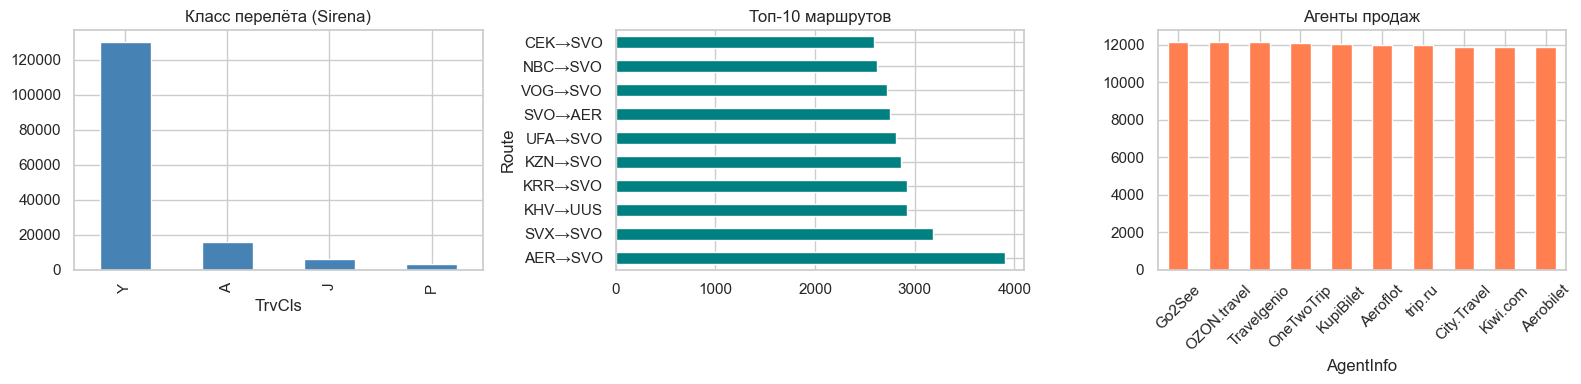

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# класс перелёта
if 'TrvCls' in sirena.columns:
    sirena['TrvCls'].value_counts().plot(kind='bar', ax=axes[0], color='steelblue')
    axes[0].set_title('Класс перелёта (Sirena)')

# маршруты
if 'From' in sirena.columns and 'Dest' in sirena.columns:
    sirena['Route'] = sirena['From'].str.strip() + '→' + sirena['Dest'].str.strip()
    sirena['Route'].value_counts().head(10).plot(kind='barh', ax=axes[1], color='teal')
    axes[1].set_title('Топ-10 маршрутов')

# агент продаж
if 'AgentInfo' in sirena.columns:
    sirena['AgentInfo'].str.strip().value_counts().head(10).plot(kind='bar', ax=axes[2], color='coral')
    axes[2].set_title('Агенты продаж')
    axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 3. YourBoardingPassDotAero


In [12]:
# Координаты полей соответствуют шаблону посадочного талона.

def parse_boarding_pass(filepath):
    df = pd.read_excel(filepath, header=None)
    def val(r, c):
        try:
            v = df.iloc[r, c]
            return str(v).strip() if pd.notna(v) else None
        except:
            return None
    return {
        'sequence':     val(0, 7),
        'title':        val(2, 0),
        'name':         val(2, 1),
        'travel_class': val(2, 7),
        'flight':       val(4, 0),
        'from_city':    val(4, 3),
        'to_city':      val(4, 7),
        'from_iata':    val(6, 3),
        'to_iata':      val(6, 7),
        'date':         val(8, 0),
        'time':         val(8, 2),
        'operated_by':  val(8, 4),
        'booking_code': val(12, 1),
        'ticket_number':val(12, 4),
        'source_file':  Path(filepath).name,
    }

xlsx_files = sorted(glob.glob(str(BASE / 'YourBoardingPassDotAero' / '*.xlsx')))
print(f'Найдено файлов: {len(xlsx_files)}')

bp_records = [parse_boarding_pass(f) for f in xlsx_files]
bp = pd.DataFrame(bp_records)
bp.replace('nan', np.nan, inplace=True)
bp['date'] = pd.to_datetime(bp['date'], errors='coerce')

name_split = bp['name'].fillna('').str.strip().str.split(expand=True)
bp['name_part1'] = name_split[0]
bp['name_part2'] = name_split[1] if 1 in name_split.columns else np.nan
bp['name_part3'] = name_split[2] if 2 in name_split.columns else np.nan

bp['full_name_key'] = bp['name'].str.upper().str.split().str.join(' ').replace('', np.nan)
bp['first_name'] = np.nan
bp['second_name'] = np.nan
bp['last_name'] = np.nan
bp['name_match_method'] = np.where(bp['full_name_key'].notna(), 'pending_reconciliation', 'no_name')

print('Форма:', bp.shape)
print('\nПримеры имён:')
bp[['title','name','name_part1','name_part2','name_part3']].head(10)

Найдено файлов: 366
Форма: (366, 23)

Примеры имён:


,title,name,name_part1,name_part2,name_part3
0,MRS,LIDIYA ZHDANOVA,LIDIYA,ZHDANOVA,None
1,MR,MAKSIM KARTASHOV,MAKSIM,KARTASHOV,None
2,MR,RADMIR GORSHKOV,RADMIR,GORSHKOV,None
3,MRS,SHULGINA MARIIA,SHULGINA,MARIIA,None
4,MRS,MAYYA NIKULINA,MAYYA,NIKULINA,None
5,MR,IAROMIR FEDOTOV,IAROMIR,FEDOTOV,None
6,MRS,NAUMOVA ESENIYA,NAUMOVA,ESENIYA,None
7,MRS,EKATERINA MAYOROVA,EKATERINA,MAYOROVA,None
8,MRS,OLESYA M LEONOVA,OLESYA,M,LEONOVA
9,MRS,PIMENOVA OLGA,PIMENOVA,OLGA,None


In [13]:
required_fields = ['name', 'flight', 'date', 'from_iata', 'to_iata']
display(bp[required_fields].notna().sum().rename('заполнено').to_frame())

,заполнено
name,366
flight,366
date,366
from_iata,366
to_iata,366


In [14]:
bp.head(10)

,sequence,title,name,travel_class,flight,from_city,to_city,from_iata,to_iata,date,time,operated_by,booking_code,ticket_number,source_file,name_part1,name_part2,name_part3,full_name_key,first_name,second_name,last_name,name_match_method
0,32,MRS,LIDIYA ZHDANOVA,Y,SU5436,VLADIVOSTOK,SEOUL,VVO,REA,2017-01-01,11:25,Operated by Some Other Airline,DYELAO,7100246988860481,YourBoardingPassDotAero-2017-01-01.xlsx,LIDIYA,ZHDANOVA,None,LIDIYA ZHDANOVA,NaN,NaN,NaN,pending_reconciliation
1,42,MR,MAKSIM KARTASHOV,Y,SU1191,KAZAN,MOSCOW,KZN,SVO,2017-01-02,12:20,Operated by Some Other Airline,JLXPWW,8023093672216494,YourBoardingPassDotAero-2017-01-02.xlsx,MAKSIM,KARTASHOV,None,MAKSIM KARTASHOV,NaN,NaN,NaN,pending_reconciliation
2,32,MR,RADMIR GORSHKOV,Y,SU2206,MOSCOW,HELSINKI,SVO,HEL,2017-01-03,09:35,Operated by Some Other Airline,TISZPO,5532637664518321,YourBoardingPassDotAero-2017-01-03.xlsx,RADMIR,GORSHKOV,None,RADMIR GORSHKOV,NaN,NaN,NaN,pending_reconciliation
3,14,MRS,SHULGINA MARIIA,Y,SU1337,ARKHANGELSK,MOSCOW,ARH,SVO,2017-01-04,21:10,Operated by Some Other Airline,JZRZYD,3401758738858423,YourBoardingPassDotAero-2017-01-04.xlsx,SHULGINA,MARIIA,None,SHULGINA MARIIA,NaN,NaN,NaN,pending_reconciliation
4,84,MRS,MAYYA NIKULINA,Y,SU6023,SAINT PETERSBURG,MOSCOW,LED,VKO,2017-01-05,19:40,Operated by Some Other Airline,TONREZ,9398520256248518,YourBoardingPassDotAero-2017-01-05.xlsx,MAYYA,NIKULINA,None,MAYYA NIKULINA,NaN,NaN,NaN,pending_reconciliation
5,42,MR,IAROMIR FEDOTOV,Y,SU43,SAINT PETERSBURG,MOSCOW,LED,SVO,2017-01-06,14:30,Operated by Some Other Airline,IBXOCT,0454489245616418,YourBoardingPassDotAero-2017-01-06.xlsx,IAROMIR,FEDOTOV,None,IAROMIR FEDOTOV,NaN,NaN,NaN,pending_reconciliation
6,72,MRS,NAUMOVA ESENIYA,Y,DL469,TEL AVIV,NEW YORK NY,TLV,JFK,2017-01-07,22:35,Operated by Some Other Airline,JLZQLT,9463459928173654,YourBoardingPassDotAero-2017-01-07.xlsx,NAUMOVA,ESENIYA,None,NAUMOVA ESENIYA,NaN,NaN,NaN,pending_reconciliation
7,92,MRS,EKATERINA MAYOROVA,Y,SU2336,MOSCOW,STUTTGART,SVO,STR,2017-01-08,08:30,Operated by Some Other Airline,JXGMHO,7959014759847115,YourBoardingPassDotAero-2017-01-08.xlsx,EKATERINA,MAYOROVA,None,EKATERINA MAYOROVA,NaN,NaN,NaN,pending_reconciliation
8,89,MRS,OLESYA M LEONOVA,Y,CI9070,PRAGUE,AMSTERDAM,PRG,AMS,2017-01-09,06:00,Operated by Some Other Airline,MYOROZ,6151942751592330,YourBoardingPassDotAero-2017-01-09.xlsx,OLESYA,M,LEONOVA,OLESYA M LEONOVA,NaN,NaN,NaN,pending_reconciliation
9,8,MRS,PIMENOVA OLGA,Y,AZ7219,MOSCOW,VERONA,SVO,VRN,2017-01-10,07:25,Operated by Some Other Airline,PBXNIZ,4024358196233127,YourBoardingPassDotAero-2017-01-10.xlsx,PIMENOVA,OLGA,None,PIMENOVA OLGA,NaN,NaN,NaN,pending_reconciliation


In [15]:
print(bp.describe(include='all').T)
print('\nПропуски:')
print(bp.isnull().sum())

                  count unique                                      top freq  \
sequence            366     99                                       86    9   
title               366      2                                       MR  184   
name                366    365                        ARSEN ZVIAGINTSEV    2   
travel_class        366      4                                        Y  309   
flight              366    365                                   DL1437    2   
from_city           366    163                                   MOSCOW   35   
to_city             366    174                                   MOSCOW   30   
from_iata           366    170                                      SVO   33   
to_iata             366    180                                      SVO   28   
date                366    NaN                                      NaN  NaN   
time                366    188                                    07:05    6   
operated_by         366      1          

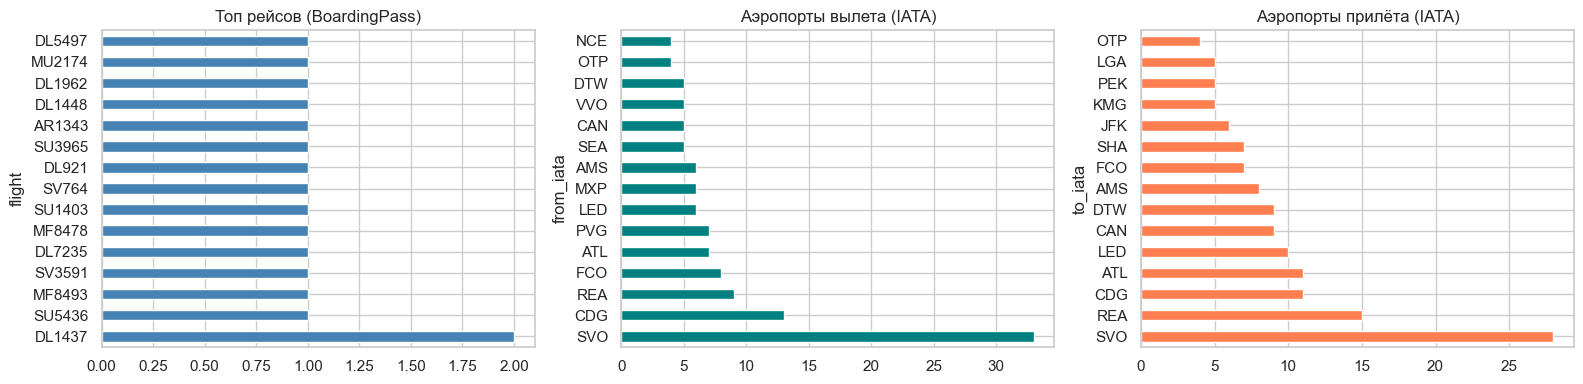

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# рейсы
bp['flight'].value_counts().head(15).plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Топ рейсов (BoardingPass)')

# аэропорты вылета
bp['from_iata'].value_counts().head(15).plot(kind='barh', ax=axes[1], color='teal')
axes[1].set_title('Аэропорты вылета (IATA)')

# аэропорты прилета
bp['to_iata'].value_counts().head(15).plot(kind='barh', ax=axes[2], color='coral')
axes[2].set_title('Аэропорты прилёта (IATA)')

plt.tight_layout()
plt.show()

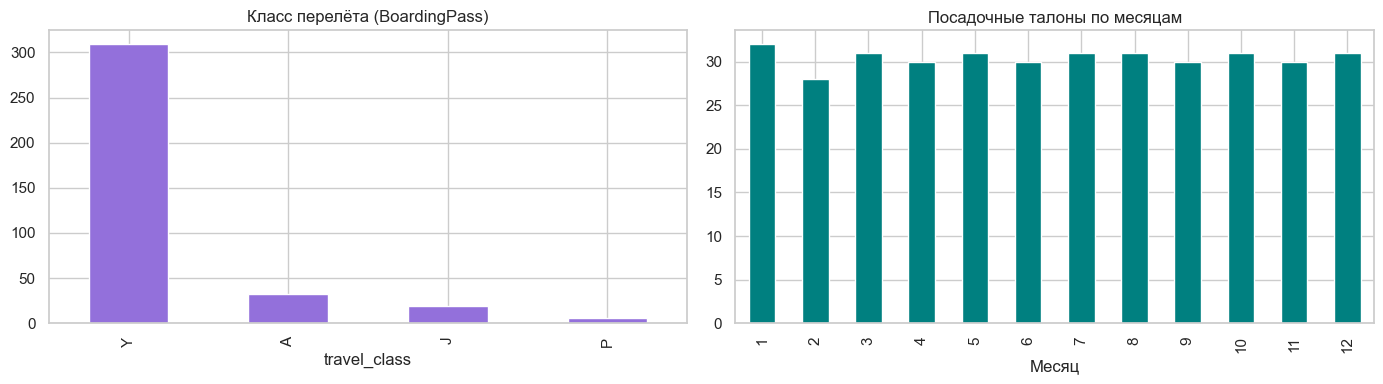

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# класс перелёта
bp['travel_class'].value_counts().plot(kind='bar', ax=axes[0], color='mediumpurple')
axes[0].set_title('Класс перелёта (BoardingPass)')

# по месяцам
bp['date'].dt.month.value_counts().sort_index().plot(kind='bar', ax=axes[1], color='teal')
axes[1].set_title('Посадочные талоны по месяцам')
axes[1].set_xlabel('Месяц')

plt.tight_layout()
plt.show()

## 4. FrequentFlyerForum-Profiles.json


In [18]:
with open(BASE / 'FrequentFlyerForum-Profiles.json', 'r', encoding='utf-8') as f:
    ff_raw = json.load(f)

profiles = ff_raw.get('Forum Profiles', [])
print(f'Профилей всего: {len(profiles):,}')
print('\nКлючи:', list(profiles[0].keys()))

Профилей всего: 66,592

Ключи: ['Registered Flights', 'NickName', 'Travel Documents', 'Sex', 'Loyality Programm', 'Real Name']


In [19]:
# разворачиваем в плоский датафрейм

rows = []
for profile in profiles:
    nickname  = profile.get('NickName', '')
    rn        = profile.get('Real Name') or {}
    first_nm  = rn.get('First Name')
    last_nm   = rn.get('Last Name')
    sex       = profile.get('Sex')
    full_name_key = f"{first_nm} {last_nm}".strip() if first_nm or last_nm else None

    # programm + number 
    lp = profile.get('Loyality Programm') or []
    ff_cards = [
        (p.get('programm', '').strip() + ' ' + str(p.get('Number', '')).strip()).strip()
        for p in lp if p.get('Number')
    ]

    # документы
    td = profile.get('Travel Documents') or []
    passports = [d.get('Passports') for d in td if d.get('Passports')]

    for flight in profile.get('Registered Flights', []):
        rows.append({
            'nickname':       nickname,
            'first_name':     first_nm,
            'last_name':      last_nm,
            'full_name_key':  full_name_key,
            'sex':            sex,
            'ff_cards':       ', '.join(ff_cards) if ff_cards else None,
            'ff_cards_list':  ff_cards,
            'passport':       passports[0] if passports else None,
            'date':           flight.get('Date'),
            'flight':         flight.get('Flight'),
            'codeshare':      flight.get('Codeshare'),
            'dep_airport':    flight.get('Departure', {}).get('Airport'),
            'dep_city':       flight.get('Departure', {}).get('City'),
            'dep_country':    flight.get('Departure', {}).get('Country'),
            'arr_airport':    flight.get('Arrival', {}).get('Airport'),
            'arr_city':       flight.get('Arrival', {}).get('City'),
            'arr_country':    flight.get('Arrival', {}).get('Country'),
        })

ff_df = pd.DataFrame(rows)
ff_df['date'] = pd.to_datetime(ff_df['date'], errors='coerce')

print(f'Записей: {len(ff_df):,}')
print(f'Уникальных профилей: {ff_df["nickname"].nunique():,}')
print(f'Профилей с реальным именем: {ff_df["full_name_key"].notna().sum():,}')
print(f'Профилей с FF-картами: {ff_df["ff_cards"].notna().sum():,}')
print()
ff_df[['nickname','first_name','last_name','ff_cards','date','flight','dep_airport','arr_airport']].head(10)


Записей: 1,308,987
Уникальных профилей: 66,592
Профилей с реальным именем: 657,755
Профилей с FF-картами: 1,124,176



,nickname,first_name,last_name,ff_cards,date,flight,dep_airport,arr_airport
0,FrequentFlyer0,None,None,"KE 889215424, DT 484697244",2017-03-04,DL3377,BOS,PIT
1,FrequentFlyer0,None,None,"KE 889215424, DT 484697244",2017-07-21,DL3630,GRB,DTW
2,FrequentFlyer0,None,None,"KE 889215424, DT 484697244",2017-03-22,DL5361,PIT,LGA
3,FrequentFlyer0,None,None,"KE 889215424, DT 484697244",2017-01-04,SU3702,SVO,WAW
4,FrequentFlyer0,None,None,"KE 889215424, DT 484697244",2017-08-08,DL3412,XNA,ATL
5,FrequentFlyer0,None,None,"KE 889215424, DT 484697244",2017-08-30,DL659,ATL,FLL
6,FrequentFlyer0,None,None,"KE 889215424, DT 484697244",2017-06-10,DL5032,ILM,ATL
7,FrequentFlyer0,None,None,"KE 889215424, DT 484697244",2017-11-10,DL3363,ATL,OAJ
8,FrequentFlyer0,None,None,"KE 889215424, DT 484697244",2017-12-14,DL1364,ATL,SMF
9,FrequentFlyer0,None,None,"KE 889215424, DT 484697244",2017-02-27,AF3616,CDG,BOS


In [20]:
print(ff_df.describe(include='all').T)
print('\nПропуски:')
print(ff_df.isnull().sum())

                 count unique                 top     freq  \
nickname       1308987  66592  FrequentFlyer60655       42   
first_name      657755    200            KRISTINA     4023   
last_name       657755   1006            CHERNYKH     1320   
full_name_key   657755  28403  ANATOLIY SAL'NIKOV      112   
sex             985901      2                Male   494134   
ff_cards       1124176  57151        KE 491999883       42   
ff_cards_list  1308987  57152                  []   184811   
passport             0      0                 NaN      NaN   
date           1308987    NaN                 NaN      NaN   
flight         1308987  24005              SU4606     2917   
codeshare      1308987      2               False  1037438   
dep_airport    1308987   1129                 SVO   133232   
dep_city       1308987   1093              Moscow   139183   
dep_country    1308987    182  Russian Federation   279299   
arr_airport    1308987   1129                 SVO   133633   
arr_city

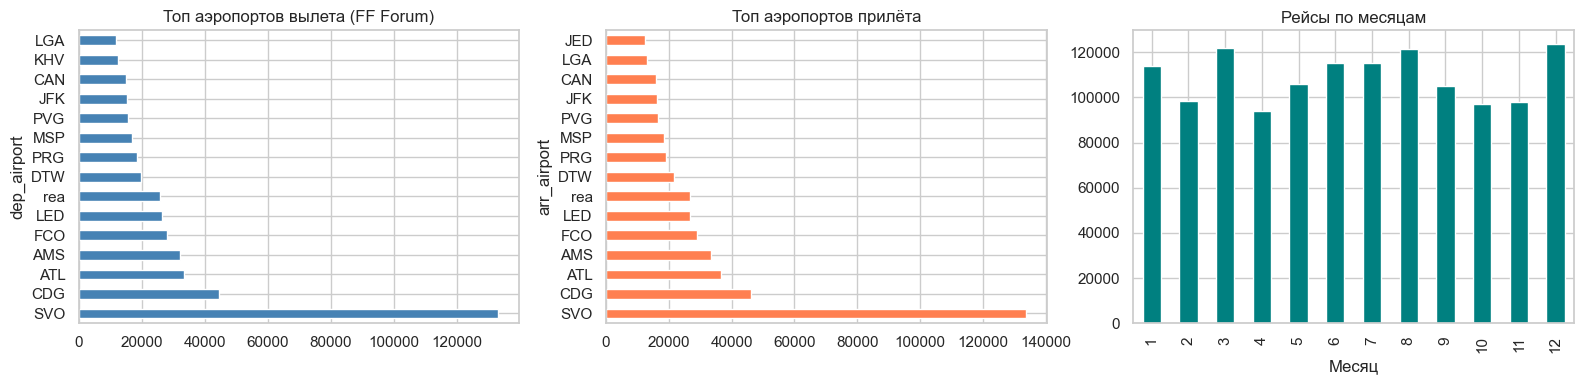

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# аэропорты вылета
ff_df['dep_airport'].value_counts().head(15).plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Топ аэропортов вылета (FF Forum)')

# аэропорты прилёта
ff_df['arr_airport'].value_counts().head(15).plot(kind='barh', ax=axes[1], color='coral')
axes[1].set_title('Топ аэропортов прилёта')

# по месяцам
ff_df['date'].dt.month.value_counts().sort_index().plot(kind='bar', ax=axes[2], color='teal')
axes[2].set_title('Рейсы по месяцам')
axes[2].set_xlabel('Месяц')

plt.tight_layout()
plt.show()

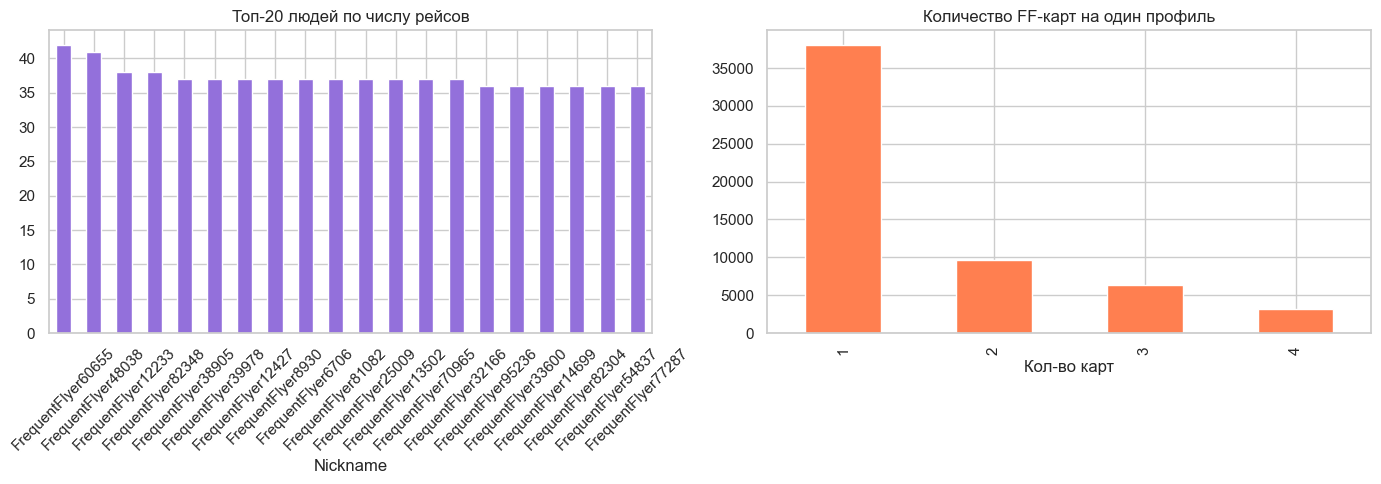

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Топ по числу рейсов
user_flights = ff_df.groupby('nickname').size().sort_values(ascending=False).head(20)
user_flights.plot(kind='bar', ax=axes[0], color='mediumpurple')
axes[0].set_title('Топ-20 людей по числу рейсов')
axes[0].set_xlabel('Nickname')
axes[0].tick_params(axis='x', rotation=45)

# FF-карт на профиль
cards_per_user = ff_df.groupby('nickname')['ff_cards'].first().dropna()
n_cards = cards_per_user.str.split(',').apply(len)
n_cards.value_counts().sort_index().plot(kind='bar', ax=axes[1], color='coral')
axes[1].set_title('Количество FF-карт на один профиль')
axes[1].set_xlabel('Кол-во карт')

plt.tight_layout()
plt.show()


## 5. PointzAggregator-AirlinesData.xml


In [23]:
tree = ET.parse(BASE / 'PointzAggregator-AirlinesData.xml')
root = tree.getroot()

rows = []
for user in root.findall('user'):
    uid = user.get('uid')
    name_el = user.find('name')
    first = name_el.get('first') if name_el is not None else None
    last = name_el.get('last') if name_el is not None else None
    
    for card in user.findall('.//card'):
        card_number = card.get('number')
        bonus = card.findtext('bonusprogramm')
        
        for act in card.findall('.//activity'):
            rows.append({
                'uid': uid,
                'first_name': first,
                'last_name': last,
                'card_number': card_number,
                'bonus_program': bonus,
                'flight_code': act.findtext('Code'),
                'date': act.findtext('Date'),
                'departure': act.findtext('Departure'),
                'arrival': act.findtext('Arrival'),
                'fare': act.findtext('Fare'),
            })

xml_df = pd.DataFrame(rows)
xml_df['date'] = pd.to_datetime(xml_df['date'], errors='coerce')
print('Форма:', xml_df.shape)
xml_df.head(10)

Форма: (436090, 10)


,uid,first_name,last_name,card_number,bonus_program,flight_code,date,departure,arrival,fare
0,613142142,IAROMIR,ZVEREV,FB 171388778,Flying Blue,KE827,2017-08-06,rea,SZX,YGRPZT
1,613142142,IAROMIR,ZVEREV,FB 171388778,Flying Blue,MU9706,2017-10-26,PEK,BSD,YSTNYV
2,103197717,VITALINA,KOROVINA,KE 696768759,Korean Air SKYPASS,DL5058,2017-09-11,CHA,ATL,YRSTKY
3,103197717,VITALINA,KOROVINA,KE 696768759,Korean Air SKYPASS,KE1,2017-04-01,rea,HNL,PRSTRU
4,103197717,VITALINA,KOROVINA,KE 696768759,Korean Air SKYPASS,DL837,2017-09-13,ATL,HNL,YGRPNG
5,103197717,VITALINA,KOROVINA,KE 696768759,Korean Air SKYPASS,SU1523,2017-02-12,NUX,SVO,YFLXPS
6,138879468,DANIL,VAVILOV,DT 980250352,Delta SkyMiles,AF4445,2017-11-11,AJA,ORY,YSTNMG
7,138879468,DANIL,VAVILOV,DT 980250352,Delta SkyMiles,AZ7545,2017-03-07,FCO,PRG,ASTNZL
8,138879468,DANIL,VAVILOV,DT 980250352,Delta SkyMiles,AF7331,2017-09-17,MLH,ORY,YSTNOE
9,138879468,DANIL,VAVILOV,DT 980250352,Delta SkyMiles,AF4102,2017-10-07,ORY,AJA,YSTNJD


In [24]:
print(xml_df.describe(include='all').T)
print('\nПропуски:')
print(xml_df.isnull().sum())

                count unique           top    freq  \
uid            436090  56943     966582620      35   
first_name     436090    274         NAZAR    2636   
last_name      436090   1210      CHERNYKH     773   
card_number    436090  88172  KE 180221844      16   
bonus_program  436090      4   Flying Blue  109647   
flight_code    436090  23849        SU4606     984   
date           436090    NaN           NaN     NaN   
departure      436090   1128           SVO   44278   
arrival        436090   1126           SVO   44528   
fare           436090  10694        YFLXHC     176   

                                        mean                  min  \
uid                                      NaN                  NaN   
first_name                               NaN                  NaN   
last_name                                NaN                  NaN   
card_number                              NaN                  NaN   
bonus_program                            NaN                

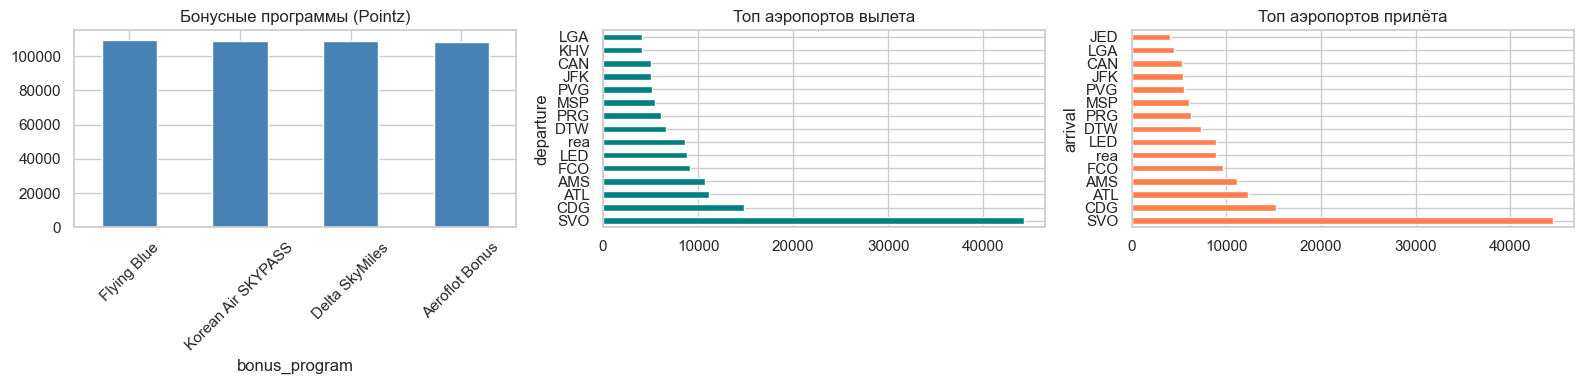

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

xml_df['bonus_program'].value_counts().head(10).plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Бонусные программы (Pointz)')
axes[0].tick_params(axis='x', rotation=45)

xml_df['departure'].value_counts().head(15).plot(kind='barh', ax=axes[1], color='teal')
axes[1].set_title('Топ аэропортов вылета')

xml_df['arrival'].value_counts().head(15).plot(kind='barh', ax=axes[2], color='coral')
axes[2].set_title('Топ аэропортов прилёта')

plt.tight_layout()
plt.show()

## 6. SkyTeam


In [26]:
# буферизуем FF-записи и достраиваем их при переходе на следующий рейс

date_pat   = re.compile(r"^'(\d{4}-\d{2}-\d{2})':")
flight_pat = re.compile(r'^  ([A-Z][A-Z0-9]{1,5}):')
from_pat   = re.compile(r'^    FROM:\s*(\S+)')
to_pat     = re.compile(r'^    TO:\s*(\S+)')
status_pat = re.compile(r'^    STATUS:\s*(\S+)')
ff_pat     = re.compile(r'^      ([A-Z]{2,3} \d+):\s*\{CLASS:\s*(\w+),\s*FARE:\s*(\w+)\}')

sky_rows = []

cur_date = cur_flight = cur_from = cur_to = cur_status = None
ff_buffer = []   

def flush_buffer():
    # записываем буферизованные FF-записи
    for rec in ff_buffer:
        rec.update({'date': cur_date, 'flight': cur_flight,
                    'from': cur_from, 'to': cur_to, 'status': cur_status})
        sky_rows.append(rec)
    ff_buffer.clear()

with open(BASE / 'SkyTeam-Exchange.yaml', 'r', encoding='utf-8') as fh:
    for line in fh:
        # новая дата - сбрасываем буфер
        m = date_pat.match(line)
        if m:
            flush_buffer()
            cur_date = m.group(1)
            cur_flight = cur_from = cur_to = cur_status = None
            continue

        # новый рейс - сбрасываем буфер 
        m = flight_pat.match(line)
        if m:
            flush_buffer()
            cur_flight = m.group(1)
            cur_from = cur_to = cur_status = None
            continue

        m = from_pat.match(line)
        if m: cur_from = m.group(1); continue

        m = to_pat.match(line)
        if m: cur_to = m.group(1); continue

        m = status_pat.match(line)
        if m: cur_status = m.group(1); continue

        # FF-запись — кладём в буфер
        m = ff_pat.match(line)
        if m:
            ff_buffer.append({'ff_card': m.group(1), 'class': m.group(2), 'fare': m.group(3)})

flush_buffer()  # последний рейс в файле

sky_df = pd.DataFrame(sky_rows)
sky_df['date'] = pd.to_datetime(sky_df['date'], errors='coerce')
print(f'Записей: {len(sky_df):,}')
print(f'Уникальных дат: {sky_df["date"].nunique()}')
print(f'Уникальных рейсов: {sky_df["flight"].nunique()}')
sky_df.head(8)

Записей: 1,687,053
Уникальных дат: 366
Уникальных рейсов: 24005


,ff_card,class,fare,date,flight,from,to,status
0,FB 520518073,Y,YRSTFN,2017-01-01,AF1145,SVO,CDG,LANDED
1,FB 18427809,Y,YGRPZR,2017-01-01,AF1844,SVO,CDG,LANDED
2,KE 993927664,Y,YRSTJQ,2017-01-01,AF4855,SVO,CDG,LANDED
3,SU 789402704,Y,YGRPAT,2017-01-01,AF4901,SVO,CDG,LANDED
4,KE 352734424,Y,YFLXKO,2017-01-01,AZ545,SVO,FCO,LANDED
5,SU 667777811,Y,YRSTXE,2017-01-01,AZ595,SVO,FCO,LANDED
6,SU 451734642,A,AGRPXS,2017-01-01,AZ7163,SVO,FCO,LANDED
7,SU 272025028,J,JSTNDU,2017-01-01,AZ7209,SVO,NAP,LANDED


In [27]:
print(sky_df.describe(include='all').T)
print('\nПропуски:')
print(sky_df.isnull().sum())

           count  unique           top     freq  \
ff_card  1687053  133186  KE 491999883       42   
class    1687053       4             Y  1412769   
fare     1687053   10816        YSTNEN      605   
date     1687053     NaN           NaN      NaN   
flight   1687053   24005        SU4606     3789   
from     1687053    1129           SVO   173127   
to       1687053    1129           SVO   170048   
status   1687053       1        LANDED  1687053   

                                  mean                  min  \
ff_card                            NaN                  NaN   
class                              NaN                  NaN   
fare                               NaN                  NaN   
date     2017-07-02 04:07:18.413730560  2017-01-01 00:00:00   
flight                             NaN                  NaN   
from                               NaN                  NaN   
to                                 NaN                  NaN   
status                             N

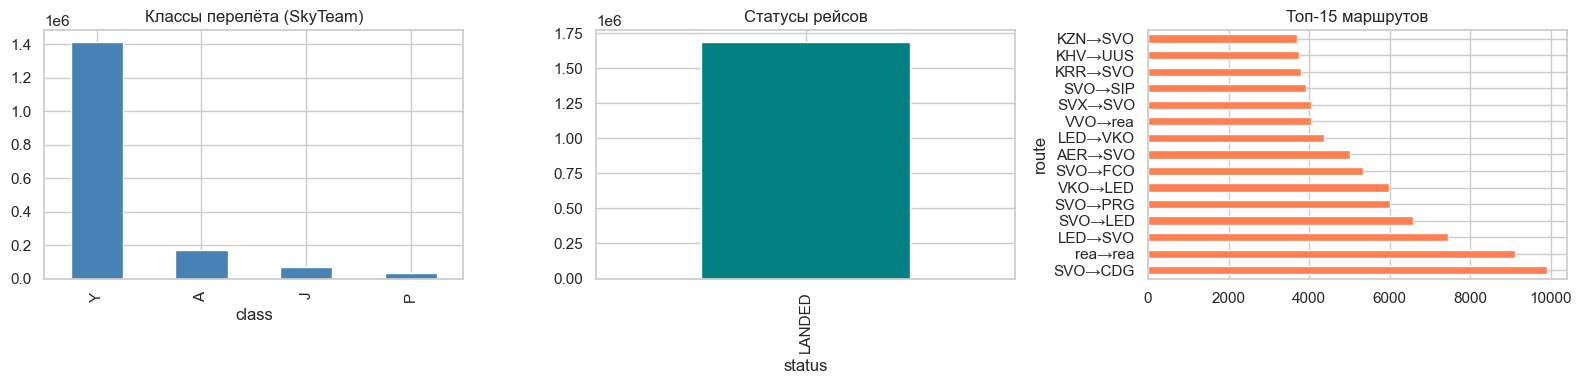

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sky_df['class'].value_counts().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Классы перелёта (SkyTeam)')

sky_df['status'].value_counts().plot(kind='bar', ax=axes[1], color='teal')
axes[1].set_title('Статусы рейсов')

# топ маршрутов
sky_df['route'] = sky_df['from'].fillna('?') + '→' + sky_df['to'].fillna('?')
sky_df['route'].value_counts().head(15).plot(kind='barh', ax=axes[2], color='coral')
axes[2].set_title('Топ-15 маршрутов')

plt.tight_layout()
plt.show()

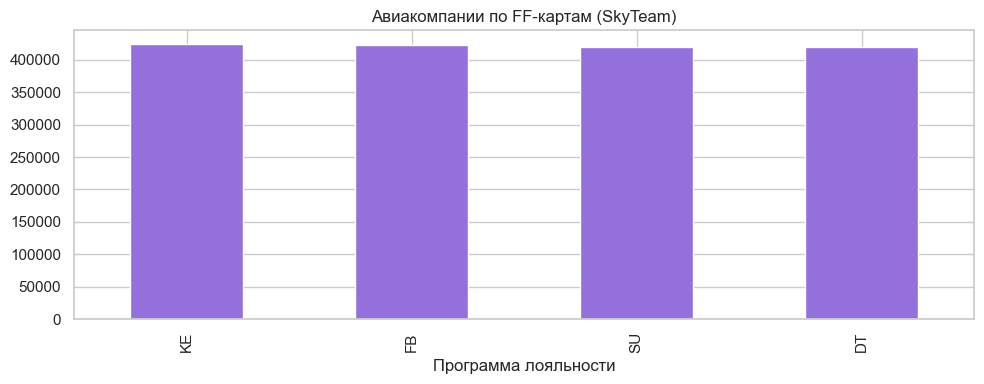

In [29]:
sky_df['ff_airline'] = sky_df['ff_card'].str.extract(r'^([A-Z]+)')
sky_df['ff_airline'].value_counts().plot(kind='bar', color='mediumpurple', figsize=(10, 4))
plt.title('Авиакомпании по FF-картам (SkyTeam)')
plt.xlabel('Программа лояльности')
plt.tight_layout()
plt.show()

## 7. Объединение всех источников в единый датасет


In [30]:
timetable_path = BASE / 'Skyteam_Timetable.pdf'
try:
    if PdfReader is None:
        raise ModuleNotFoundError
    timetable_reader = PdfReader(timetable_path)
    timetable_intro = '\n'.join(page.extract_text() or '' for page in timetable_reader.pages[:5])
    coverage = re.search(r'Covers period:\s*(.+)', timetable_intro)
    timetable_meta = pd.DataFrame([{
        'source': 'SkyTeam Timetable PDF', 'pages': len(timetable_reader.pages),
        'coverage': coverage.group(1).strip() if coverage else np.nan,
        'fields': 'from, to, validity, days, dep_time, arr_time, flight, aircraft, travel_time',
        'role': 'справочная проверка расписания, не источник идентичности пассажира',
    }])
except ModuleNotFoundError:
    timetable_meta = pd.DataFrame([{
        'source': 'SkyTeam Timetable PDF', 'pages': np.nan, 'coverage': np.nan,
        'fields': 'не прочитано: pypdf не установлен',
        'role': 'не участвует в master-датасете и не влияет на анализ пассажиров',
    }])
display(timetable_meta)

# унификация аэропортов

def norm_airport(value):
    if pd.isna(value):
        return np.nan
    value = str(value).upper().strip()
    return value if value and value not in {'NAN', 'NONE'} else np.nan

def norm_id(value):
    return np.nan if pd.isna(value) else re.sub(r'[^A-Z0-9]', '', str(value).upper()) or np.nan

def airport_context_key(data, id_col):
    return (data['date'].dt.strftime('%Y-%m-%d').fillna('') + '|' +
            data['flight'].fillna('').astype(str).str.strip() + '|' +
            data[id_col].map(norm_id).fillna(''))

boarding_airports = boarding[['FlightDate', 'FlightNumber', 'PassengerDocument', 'TicketNumber', 'Destination']].rename(columns={
    'FlightDate': 'date', 'FlightNumber': 'flight', 'PassengerDocument': 'doc_number',
    'TicketNumber': 'ticket_number', 'Destination': 'city'}).copy()
boarding_airports['date'] = pd.to_datetime(boarding_airports['date'], errors='coerce')
boarding_airports['flight'] = boarding_airports['flight'].astype('string').str.strip()
boarding_airports['doc_number'] = boarding_airports['doc_number'].astype('string').str.strip()
boarding_airports['ticket_number'] = boarding_airports['ticket_number'].astype('string').str.strip()
boarding_airports['city'] = boarding_airports['city'].map(norm_airport)
sirena_airports = sirena[['DepartDate', 'FlightCode', 'TravelDoc', 'e-Ticket', 'Dest']].rename(columns={
    'DepartDate': 'date', 'FlightCode': 'flight', 'TravelDoc': 'doc_number',
    'e-Ticket': 'ticket_number', 'Dest': 'iata'}).copy()
sirena_airports['date'] = pd.to_datetime(sirena_airports['date'], errors='coerce')
sirena_airports['flight'] = sirena_airports['flight'].astype('string').str.strip()
sirena_airports['doc_number'] = sirena_airports['doc_number'].astype('string').str.strip()
sirena_airports['ticket_number'] = sirena_airports['ticket_number'].astype('string').str.strip()
sirena_airports['iata'] = sirena_airports['iata'].map(norm_airport)

context_maps = {}
for id_col in ['doc_number', 'ticket_number']:
    matched = boarding_airports.dropna(subset=[id_col, 'city']).merge(
        sirena_airports.dropna(subset=[id_col, 'iata'])[['date', 'flight', id_col, 'iata']],
        on=['date', 'flight', id_col])
    matched['key'] = airport_context_key(matched, id_col)
    context_maps[id_col] = matched.groupby('key')['iata'].agg(
        lambda x: x.mode().iat[0] if len(x.mode()) == 1 else np.nan).to_dict()
doc_matched = boarding_airports.dropna(subset=['doc_number', 'city']).merge(
    sirena_airports.dropna(subset=['doc_number', 'iata'])[['date', 'flight', 'doc_number', 'iata']],
    on=['date', 'flight', 'doc_number'])
city_to_iata = doc_matched.groupby('city')['iata'].agg(
    lambda x: x.mode().iat[0] if len(x.mode()) == 1 else np.nan).to_dict()
iata_to_city = {iata: city for city, iata in city_to_iata.items() if pd.notna(iata)}
iata_to_city.update({'SVO': 'MOSCOW', 'DME': 'MOSCOW', 'VKO': 'MOSCOW', 'ZIA': 'MOSCOW',
                     'LED': 'SAINT PETERSBURG'})
boarding['doc_context'] = airport_context_key(boarding_airports, 'doc_number')
boarding['ticket_context'] = airport_context_key(boarding_airports, 'ticket_number')
boarding['to_airport_std'] = (boarding['doc_context'].map(context_maps['doc_number'])
    .combine_first(boarding['ticket_context'].map(context_maps['ticket_number']))
    .combine_first(boarding['Destination'].map(norm_airport).map(city_to_iata)))
print(f'Справочник: {len(city_to_iata)} городов; точных связей по документу: {len(context_maps["doc_number"]):,}')

b_unified = pd.DataFrame({
    'source':         'BoardingData',
    'date':           boarding['FlightDate'],
    'flight':         boarding['FlightNumber'],
    'from_airport':   np.nan,
    'to_airport':     boarding['to_airport_std'],
    'doc_number':     boarding['PassengerDocument'],
    'booking_code':   boarding['BookingCode'],
    'ticket_number':  boarding['TicketNumber'],
    'ff_card':        np.nan,
    'full_name_key':  boarding['full_name_key'],
    'travel_class':   np.nan,
    'fare':           np.nan,
})

s_unified = pd.DataFrame({
    'source':         'Sirena',
    'date':           sirena['DepartDate'],
    'flight':         sirena['FlightCode'],
    'from_airport':   sirena['From'].map(norm_airport),
    'to_airport':     sirena['Dest'].map(norm_airport),
    'doc_number':     sirena['TravelDoc'],
    'booking_code':   sirena['Code'],
    'ticket_number':  sirena['e-Ticket'],
    'ff_card':        sirena['PaxAdditionalInfo'].str.extract(r'FF#(.+)')[0].str.strip(),
    'full_name_key':  sirena['full_name_key'],
    'travel_class':   sirena['TrvCls'],
    'fare':           sirena['Fare'],
})

st_unified = pd.DataFrame({
    'source':         'SkyTeam',
    'date':           sky_df['date'],
    'flight':         sky_df['flight'],
    'from_airport':   sky_df['from'].map(norm_airport),
    'to_airport':     sky_df['to'].map(norm_airport),
    'doc_number':     np.nan,
    'booking_code':   np.nan,
    'ticket_number':  np.nan,
    'ff_card':        sky_df['ff_card'],
    'full_name_key':  np.nan,
    'travel_class':   sky_df['class'],
    'fare':           sky_df['fare'],
})

px_unified = pd.DataFrame({
    'source':         'Pointz',
    'date':           xml_df['date'],
    'flight':         xml_df['flight_code'],
    'from_airport':   xml_df['departure'].map(norm_airport),
    'to_airport':     xml_df['arrival'].map(norm_airport),
    'doc_number':     np.nan,
    'booking_code':   np.nan,
    'ticket_number':  np.nan,
    'ff_card':        xml_df['card_number'],
    'full_name_key':  (xml_df['first_name'].fillna('') + ' ' + xml_df['last_name'].fillna('')).str.strip(),
    'travel_class':   np.nan,
    'fare':           xml_df['fare'],
})

# у профиля FF Forum может быть несколько карт - разворачиваем их

ff_events = ff_df.explode('ff_cards_list').copy()
ff_events['ff_card_link'] = ff_events['ff_cards_list'].fillna(ff_events['ff_cards'])

ff_unified = pd.DataFrame({
    'source':         'FF_Forum',
    'date':           ff_events['date'],
    'flight':         ff_events['flight'],
    'from_airport':   ff_events['dep_airport'].map(norm_airport),
    'to_airport':     ff_events['arr_airport'].map(norm_airport),
    'doc_number':     ff_events['passport'],
    'booking_code':   np.nan,
    'ticket_number':  np.nan,
    'ff_card':        ff_events['ff_card_link'],
    'full_name_key':  ff_events['full_name_key'],
    'travel_class':   np.nan,
    'fare':           np.nan,
})

def normalize_name(value):
    if pd.isna(value):
        return ''
    value = unicodedata.normalize('NFKD', str(value)).upper()
    return re.sub(r'[^A-ZА-Я]', '', value)

def normalize_id(value):
    return '' if pd.isna(value) else re.sub(r'\s+', '', str(value)).upper()

name_refs = pd.concat([b_unified, s_unified, px_unified, ff_unified], ignore_index=True)[
    ['full_name_key', 'booking_code', 'ticket_number']
].dropna(subset=['full_name_key'])
names_by_key, pnr_to_names, ticket_to_names = {}, {}, {}
for ref in name_refs.itertuples(index=False):
    canonical = ' '.join(str(ref.full_name_key).upper().split())
    key = normalize_name(canonical)
    if not key:
        continue
    names_by_key.setdefault(key, set()).add(canonical)
    pnr, ticket = normalize_id(ref.booking_code), normalize_id(ref.ticket_number)
    if pnr:
        pnr_to_names.setdefault(pnr, set()).add(key)
    if ticket:
        ticket_to_names.setdefault(ticket, set()).add(key)

def resolve_boarding_pass_name(row):
    raw_name = row['full_name_key']
    if pd.isna(raw_name):
        return pd.Series([np.nan, np.nan, np.nan, np.nan, 'no_name'])
    tokens = str(raw_name).split()
    candidates = {normalize_name(' '.join(order)) for order in itertools.permutations(tokens)}
    linked = (pnr_to_names.get(normalize_id(row['booking_code']), set()) |
              ticket_to_names.get(normalize_id(row['ticket_number']), set()))
    matches, method = candidates & linked, 'pnr_or_ticket'
    if not matches:
        matches, method = candidates & set(names_by_key), 'exact_name'
    canonical_matches = {name for key in matches for name in names_by_key[key]}
    if len(canonical_matches) != 1:
        # Исходное имя — полноценный ключ независимо от результата сверки.
        return pd.Series([raw_name, np.nan, np.nan, np.nan,
                          'ambiguous' if canonical_matches else 'unmatched'])
    canonical = canonical_matches.pop()
    parts = canonical.split()
    return pd.Series([canonical, parts[0], ' '.join(parts[1:-1]) or np.nan, parts[-1], method])

bp[['full_name_key', 'first_name', 'second_name', 'last_name', 'name_match_method']] = bp.apply(resolve_boarding_pass_name, axis=1)
print('Сверка ФИО после загрузки всех источников:')
print(bp['name_match_method'].value_counts(dropna=False))

bp_unified = pd.DataFrame({
    'source':         'BoardingPass',
    'date':           bp['date'],
    'flight':         bp['flight'],
    'from_airport':   bp['from_iata'].map(norm_airport),
    'to_airport':     bp['to_iata'].map(norm_airport),
    'doc_number':     np.nan,
    'booking_code':   bp['booking_code'],
    'ticket_number':  bp['ticket_number'],
    'ff_card':        np.nan,
    'full_name_key':  bp['full_name_key'],
    'travel_class':   bp['travel_class'],
    'fare':           np.nan,
})

for source_frame in [b_unified, s_unified, st_unified, px_unified, ff_unified, bp_unified]:
    source_frame['from_city'] = source_frame['from_airport'].map(iata_to_city).fillna(source_frame['from_airport'])
    source_frame['to_city'] = source_frame['to_airport'].map(iata_to_city).fillna(source_frame['to_airport'])

master = pd.concat([b_unified, s_unified, st_unified, px_unified, ff_unified, bp_unified], ignore_index=True)
master['date'] = pd.to_datetime(master['date'], errors='coerce')

def normalize_entity_id(value):
    if pd.isna(value):
        return np.nan
    value = re.sub(r'[^A-Z0-9]', '', str(value).upper())
    return value if value and value != 'NAN' else np.nan

identity_keys_for_manual_review = {
    'doc_number': {normalize_entity_id('8248 013778')},
    'ff_card': {normalize_entity_id('FB 139888197')},
}

def build_entity_ids(data, identity_fields=('doc_number', 'ticket_number', 'ff_card')):
    parent = np.arange(len(data), dtype=np.int64)

    def find(node):
        while parent[node] != node:
            parent[node] = parent[parent[node]]
            node = parent[node]
        return node

    def union(left, right):
        left, right = find(left), find(right)
        if left != right:
            parent[right] = left

    for field in identity_fields:
        keys = data[field].map(normalize_entity_id)
        keys = keys.mask(keys.isin(identity_keys_for_manual_review.get(field, set())))
        duplicate_keys = keys[keys.notna() & keys.duplicated(keep=False)]
        for row_ids in duplicate_keys.groupby(duplicate_keys, sort=False).groups.values():
            row_ids = list(row_ids)
            for row_id in row_ids[1:]:
                union(row_ids[0], row_id)

    return pd.Series([f'entity_{find(row_id)}' for row_id in range(len(data))], index=data.index)

master['entity_id'] = build_entity_ids(master)

print('Мастер-датасет:', master.shape)
linked_records = master['entity_id'].duplicated(keep=False).sum()
print(f'Записей, связанных с другой записью по документу, билету или FF-карте: {linked_records:,}')
print('\nПо источникам:')
print(master['source'].value_counts())
print(f'\nЗаписей с full_name_key: {master["full_name_key"].notna().sum():,}')


,source,pages,coverage,fields,role
0,SkyTeam Timetable PDF,27514,01 Nov 2018 through 31 Jan 2019,"from, to, validity, days, dep_time, ...","справочная проверка расписания, не и..."


Справочник: 48 городов; точных связей по документу: 70,093
Сверка ФИО после загрузки всех источников:
name_match_method
exact_name       216
unmatched        144
ambiguous          4
pnr_or_ticket      2
Name: count, dtype: int64
Мастер-датасет: (4366355, 15)
Записей, связанных с другой записью по документу, билету или FF-карте: 4,150,571

По источникам:
source
FF_Forum        1931942
SkyTeam         1687053
Pointz           436090
Sirena           155757
BoardingData     155147
BoardingPass        366
Name: count, dtype: int64

Записей с full_name_key: 1,720,599


In [31]:
bp[bp['name_match_method'] == 'ambiguous']

,sequence,title,name,travel_class,flight,from_city,to_city,from_iata,to_iata,date,time,operated_by,booking_code,ticket_number,source_file,name_part1,name_part2,name_part3,full_name_key,first_name,second_name,last_name,name_match_method
39,46,MR,MARSEL' GORDEEV,Y,SU320,MOSCOW,MALE,SVO,MLE,2017-02-09,21:50,Operated by Some Other Airline,BGJTXS,6661718720042729,YourBoardingPassDotAero-2017-02-09.xlsx,MARSEL',GORDEEV,None,MARSEL' GORDEEV,NaN,NaN,NaN,ambiguous
137,54,MRS,PETUKHOVA ELMIRA,Y,KL1631,AMSTERDAM,MILAN,AMS,MXP,2017-05-18,14:40,Operated by Some Other Airline,GIPXLI,6932875988779898,YourBoardingPassDotAero-2017-05-18.xlsx,PETUKHOVA,ELMIRA,None,PETUKHOVA ELMIRA,NaN,NaN,NaN,ambiguous
196,61,MR,SAVELEV STEPAN,Y,CZ7217,LONDON,NEWCASTLE,LHR,NCL,2017-07-16,17:35,Operated by Some Other Airline,XFYLEZ,6527845233065735,YourBoardingPassDotAero-2017-07-16.xlsx,SAVELEV,STEPAN,None,SAVELEV STEPAN,NaN,NaN,NaN,ambiguous
233,2,MR,DANIEL' LEVIN,Y,MF9062,BRUSSELS,ANTWERP,BRU,ZWE,2017-08-22,06:10,Operated by Some Other Airline,SBIDSL,4022412524376333,YourBoardingPassDotAero-2017-08-22.xlsx,DANIEL',LEVIN,None,DANIEL' LEVIN,NaN,NaN,NaN,ambiguous


In [32]:
master.head(10)

,source,date,flight,from_airport,to_airport,doc_number,booking_code,ticket_number,ff_card,full_name_key,travel_class,fare,from_city,to_city,entity_id
0,BoardingData,2017-03-22,SU1369,NaN,SVO,2879 096860,FRNINO,6625956945991971,NaN,SAVELII VIKTOROVICH RUSANOV,NaN,NaN,NaN,MOSCOW,entity_0
1,BoardingData,2017-03-18,SU1180,NaN,VOG,1788 173211,NaN,1643715499224676,NaN,LEV MARKOVICH ISAEV,NaN,NaN,NaN,VOLGOGRAD,entity_1
2,BoardingData,2017-03-18,SU1180,NaN,VOG,4396 926588,VWNYGF,6247422701565929,NaN,NIKOLAI I. NIKOLSKII,NaN,NaN,NaN,VOLGOGRAD,entity_2
3,BoardingData,2017-03-18,SU1180,NaN,VOG,2595 919752,WQFFUE,NaN,NaN,ANATOLII PETROVICH SHILOV,NaN,NaN,NaN,VOLGOGRAD,entity_3
4,BoardingData,2017-03-12,SU6284,NaN,SVO,6775 516990,NaN,NaN,NaN,MIROSLAVA VIACHESLAVOVNA SEMENOVA,NaN,NaN,NaN,MOSCOW,entity_4
5,BoardingData,2017-03-12,SU6284,NaN,SVO,0058 142289,JJADFB,7467749130398378,NaN,ARTEM EDUARDOVICH KAPUSTIN,NaN,NaN,NaN,MOSCOW,entity_5
6,BoardingData,2017-07-29,SU1281,NaN,SVO,6600 251370,NaN,5954073786122008,NaN,ZARINA E. TITOVA,NaN,NaN,NaN,MOSCOW,entity_6
7,BoardingData,2017-07-29,SU1281,NaN,SVO,0078 271703,WGKZTB,2264717979478322,NaN,SAMIR GORDEEVICH BARSUKOV,NaN,NaN,NaN,MOSCOW,entity_7
8,BoardingData,2017-04-07,SU1482,NaN,KJA,0595 142701,POFVPI,NaN,NaN,RAMIL E. ROZHKOV,NaN,NaN,NaN,KRASNOYARSK,entity_8
9,BoardingData,2017-04-07,SU1482,NaN,KJA,0916 040520,NaN,1678047813210634,NaN,ALBINA V. KONSTANTINOVA,NaN,NaN,NaN,KRASNOYARSK,entity_9


In [33]:
print(master.describe(include='all').T)

                 count  unique               top     freq  \
source         4366355       6          FF_Forum  1931942   
date           4366355     NaN               NaN      NaN   
flight         4366355   24005            SU4606    14938   
from_airport   4211073    1127               SVO   454449   
to_airport     4366211    1127               SVO   587583   
doc_number      310904  101662       7126 372174       26   
booking_code    233509  194558            AQSSTI        4   
ticket_number   233470  233459  4318992729905379        2   
ff_card        3922191  133360      FB 995659943       88   
full_name_key  1720599  209431    NIKITA BYCHKOV      267   
travel_class   1843176       4                 Y  1543246   
fare           2278900   10816            YSTNEN      817   
from_city      4211073    1125            MOSCOW   473038   
to_city        4366211    1125            MOSCOW   598320   
entity_id      4366355  375290       entity_5408      186   

                       

In [34]:
print('Пропуски')
missing = master.isnull().sum()
missing_pct = (missing / len(master) * 100).round(1)
pd.DataFrame({'missing': missing, '%': missing_pct})

Пропуски


,missing,%
source,0,0.0
date,0,0.0
flight,0,0.0
from_airport,155282,3.6
to_airport,144,0.0
doc_number,4055451,92.9
booking_code,4132846,94.7
ticket_number,4132885,94.7
ff_card,444164,10.2
full_name_key,2645756,60.6


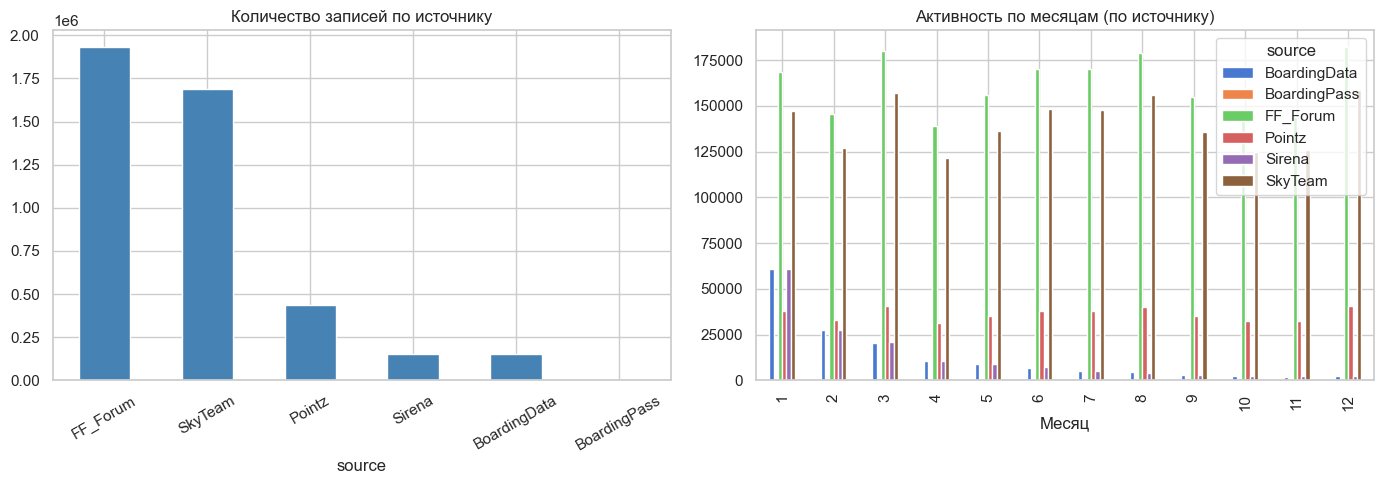

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# вклад каждого источника
master['source'].value_counts().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Количество записей по источнику')
axes[0].tick_params(axis='x', rotation=30)

# по месяцам
master['month'] = master['date'].dt.month
master.groupby(['month', 'source']).size().unstack(fill_value=0).plot(kind='bar', ax=axes[1])
axes[1].set_title('Активность по месяцам (по источнику)')
axes[1].set_xlabel('Месяц')

plt.tight_layout()
plt.show()

## 8. Поиск аномалий

In [36]:
anomaly_specs = [
    ('Общий документ', 'doc_number', '8248013778', 'RAMIL ALBERTOVICH BUROV; GORDEI MAKAREVICH GLEBOV'),
    ('Общая FF-карта', 'ff_card', 'FB139888197', 'OLESYA GOLOVINA; ROMAN MASLENNIKOV'),
]

anomaly_summary = []
for anomaly_type, field, key, people in anomaly_specs:
    evidence = master[master[field].map(normalize_entity_id).eq(key)].copy()
    anomaly_summary.append({
        'аномалия': anomaly_type,
        'идентификатор': key,
        'люди': people,
        'источники': ', '.join(sorted(evidence['source'].unique())),
        'записей': len(evidence),
    })

display(pd.DataFrame(anomaly_summary))

for anomaly_type, field, key, _ in anomaly_specs:
    evidence = master[master[field].map(normalize_entity_id).eq(key)]
    evidence = evidence.dropna(subset=['full_name_key']).sort_values(['date', 'flight'])
    evidence = evidence.drop_duplicates(['full_name_key', 'date', 'flight'])
    print(f'\n{anomaly_type}: {key}')
    display(evidence[['source', 'date', 'flight', 'full_name_key', 'doc_number', 'ff_card', 'ticket_number']])


,аномалия,идентификатор,люди,источники,записей
0,Общий документ,8248013778,RAMIL ALBERTOVICH BUROV; GORDEI MAKA...,"BoardingData, Sirena",6
1,Общая FF-карта,FB139888197,OLESYA GOLOVINA; ROMAN MASLENNIKOV,"FF_Forum, Pointz, SkyTeam",62



Общий документ: 8248013778


,source,date,flight,full_name_key,doc_number,ff_card,ticket_number
150151,BoardingData,2017-01-03,SU1273,RAMIL ALBERTOVICH BUROV,8248 013778,NaN,7230123462656045
92874,BoardingData,2017-01-16,SU1057,GORDEI M. GLEBOV,8248 013778,NaN,2082229451418171
248299,Sirena,2017-01-16,SU1057,GORDEY MAKAREVICH GLEBOV,8248 013778,NaN,2082229451418171
83246,BoardingData,2017-03-09,SU1276,GORDEI M. GLEBOV,8248 013778,NaN,5858732412927507
134532,BoardingData,2017-03-10,SU1281,GORDEI MAKAREVICH GLEBOV,8248 013778,NaN,NaN



Общая FF-карта: FB139888197


,source,date,flight,full_name_key,doc_number,ff_card,ticket_number
3819351,FF_Forum,2017-01-05,SU1459,OLESYA GOLOVINA,None,FB 139888197,NaN
2310808,Pointz,2017-01-18,SU1120,OLESYA GOLOVINA,NaN,FB 139888197,NaN
3819367,FF_Forum,2017-02-19,SU6562,OLESYA GOLOVINA,None,FB 139888197,NaN
2128007,Pointz,2017-02-22,MU8332,ROMAN MASLENNIKOV,NaN,FB 139888197,NaN
3819355,FF_Forum,2017-03-23,SU6621,OLESYA GOLOVINA,None,FB 139888197,NaN
3819375,FF_Forum,2017-03-29,OK4350,OLESYA GOLOVINA,None,FB 139888197,NaN
2128005,Pointz,2017-04-06,MU218,ROMAN MASLENNIKOV,NaN,FB 139888197,NaN
3819343,FF_Forum,2017-05-01,SV567,OLESYA GOLOVINA,None,FB 139888197,NaN
3819303,FF_Forum,2017-05-18,SV1846,OLESYA GOLOVINA,None,FB 139888197,NaN
2310810,Pointz,2017-05-30,SV1654,OLESYA GOLOVINA,NaN,FB 139888197,NaN


## 9. Качество данных и кандидаты на проверку

In [37]:
def normalize_identifier(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip().upper()
    return value if value and value != 'NAN' else np.nan

def normalize_person_name(value):
    if pd.isna(value):
        return np.nan
    return re.sub(r'[^A-ZА-Я]', '', str(value).upper()) or np.nan

identity_columns = ['doc_number', 'booking_code', 'ticket_number', 'ff_card', 'full_name_key']
quality_report = (
    master.groupby('source')[identity_columns]
    .agg(lambda col: round(col.notna().mean() * 100, 1))
    .rename(columns=lambda col: f'{col}_filled_pct')
)
display(quality_report.style.format('{:.1f}%').set_caption('Заполненность идентификационных полей по источникам'))

anomaly_events = master[['source', 'date', 'flight', 'from_airport', 'to_airport', 'doc_number', 'ff_card', 'full_name_key']].copy()
anomaly_events['doc_key'] = anomaly_events['doc_number'].map(normalize_identifier)
anomaly_events['ff_key'] = anomaly_events['ff_card'].map(normalize_identifier)
anomaly_events['name_key'] = anomaly_events['full_name_key'].map(normalize_person_name)

def profile_flags(data, entity_col, entity_type):
    data = data.dropna(subset=[entity_col]).copy()
    profiles = data.groupby(entity_col).agg(
        events=('source', 'size'),
        sources=('source', 'nunique'),
        active_days=('date', 'nunique'),
        flights=('flight', 'nunique'),
        names=('name_key', 'nunique'),
        routes=('to_airport', 'nunique'),
    )
    # порог
    high_volume_threshold = profiles['events'].quantile(0.995)
    profiles['flag_name_conflict'] = profiles['names'].gt(1)
    profiles['flag_high_volume'] = profiles['events'].ge(high_volume_threshold)
    profiles['flag_multi_source'] = profiles['sources'].gt(1)
    profiles['risk_score'] = (
        profiles['flag_name_conflict'].astype(int) * 3
        + profiles['flag_high_volume'].astype(int) * 2
        + profiles['flag_multi_source'].astype(int)
    )
    profiles['entity_type'] = entity_type
    profiles['high_volume_threshold'] = high_volume_threshold
    return profiles.reset_index().rename(columns={entity_col: 'entity_key'})

document_profiles = profile_flags(anomaly_events, 'doc_key', 'document')
ff_profiles = profile_flags(anomaly_events, 'ff_key', 'ff_card')
suspect_profiles = pd.concat([document_profiles, ff_profiles], ignore_index=True)
suspect_profiles = suspect_profiles.query('risk_score > 0').sort_values(
    ['risk_score', 'events', 'sources'], ascending=False
)

flag_summary = pd.DataFrame({
    'rule': [
        'Один идентификатор связан с несколькими вариантами ФИО',
        'Идентификатор входит в верхние 0.5% по числу записей',
        'Идентификатор присутствует в двух и более источниках',
    ],
    'meaning': [
        'Проверить транслитерацию, совместное бронирование и возможную подмену данных',
        'Проверить необычно интенсивную активность',
        'Подтвердить связь датой, рейсом, PNR или билетом',
    ],
    'document_profiles': [
        int(document_profiles['flag_name_conflict'].sum()),
        int(document_profiles['flag_high_volume'].sum()),
        int(document_profiles['flag_multi_source'].sum()),
    ],
    'ff_card_profiles': [
        int(ff_profiles['flag_name_conflict'].sum()),
        int(ff_profiles['flag_high_volume'].sum()),
        int(ff_profiles['flag_multi_source'].sum()),
    ],
})
display(flag_summary)

display(suspect_profiles.head(50))


,doc_number_filled_pct,booking_code_filled_pct,ticket_number_filled_pct,ff_card_filled_pct,full_name_key_filled_pct
source,,,,,
BoardingData,100.0%,49.9%,49.9%,0.0%,100.0%
BoardingPass,0.0%,100.0%,100.0%,0.0%,100.0%
FF_Forum,0.0%,0.0%,0.0%,90.4%,50.4%
Pointz,0.0%,0.0%,0.0%,100.0%,100.0%
Sirena,100.0%,100.0%,100.0%,33.3%,100.0%
SkyTeam,0.0%,0.0%,0.0%,100.0%,0.0%


,rule,meaning,document_profiles,ff_card_profiles
0,Один идентификатор связан с нескольк...,"Проверить транслитерацию, совместное...",48152,37253
1,Идентификатор входит в верхние 0.5% ...,Проверить необычно интенсивную актив...,591,712
2,Идентификатор присутствует в двух и ...,"Подтвердить связь датой, рейсом, PNR...",54818,132919


,entity_key,events,sources,active_days,flights,names,routes,flag_name_conflict,flag_high_volume,flag_multi_source,risk_score,entity_type,high_volume_threshold
168170,FB 995659943,88,4,36,36,2,27,True,True,True,6,ff_card,64.0
201237,KE 986237392,87,3,41,39,2,21,True,True,True,6,ff_card,64.0
139321,FB 21832740,81,4,36,34,2,24,True,True,True,6,ff_card,64.0
185045,KE 552602937,81,4,36,36,2,29,True,True,True,6,ff_card,64.0
202390,SU 115633824,81,3,37,37,2,26,True,True,True,6,ff_card,64.0
136294,FB 137756504,80,3,35,35,2,30,True,True,True,6,ff_card,64.0
190634,KE 7030852,79,4,32,32,2,22,True,True,True,6,ff_card,64.0
202093,SU 108476985,79,4,33,33,2,24,True,True,True,6,ff_card,64.0
223176,SU 679124867,79,4,32,32,2,25,True,True,True,6,ff_card,64.0
158279,FB 724963067,78,4,34,34,2,23,True,True,True,6,ff_card,64.0


## 10. Перемещение в разрезе пассажира

Событий с идентификатором: 4,181,178; уникальных поездок после дедупликации: 2,762,359
Несостыковок маршрута: 181,542 у 71,956 идентификаторов.


,person_key,prev_date,prev_to,prev_to_city,date,from_airport,from_city,to_airport,flight,gap_days
2,00 0213523,2017-01-08,SVO,MOSCOW,2017-07-20,IKT,IRKUTSK,SVO,SU1563,193.0
28,00 1309405,2017-01-26,KHV,KHABAROVSK,2017-06-10,HMA,KHANTY,SVO,SU1383,135.0
81,00 4452390,2017-02-03,SVO,MOSCOW,2017-04-08,REN,ORENBURG,SVO,SU1247,64.0
118,00 6873527,2017-03-15,CEK,CHELYABINSK,2017-06-22,PEE,PERM,SVO,SU1395,99.0
156,00 9710970,2017-02-11,ROV,ROSTOV,2017-03-15,SVO,MOSCOW,NUX,SU1522,32.0
314,0006 215258,2017-04-08,SVO,MOSCOW,2017-08-23,SVX,YEKATERINBURG,SVO,SU1413,137.0
343,0008 079585,2017-01-06,SVO,MOSCOW,2017-09-10,KGD,KALININGRAD,SVO,SU1007,247.0
373,0009 129566,2017-12-12,KZN,KAZAN,2017-12-16,SVO,MOSCOW,VOZ,SU1350,4.0
404,0010 675893,2017-02-07,OVB,NOVOSIBIRSK,2017-06-21,UUS,YUZHNO,SVO,SU6284,134.0
421,0011 103224,2017-04-15,KJA,KRASNOYARSK,2017-05-28,PEE,PERM,SVO,SU1393,43.0


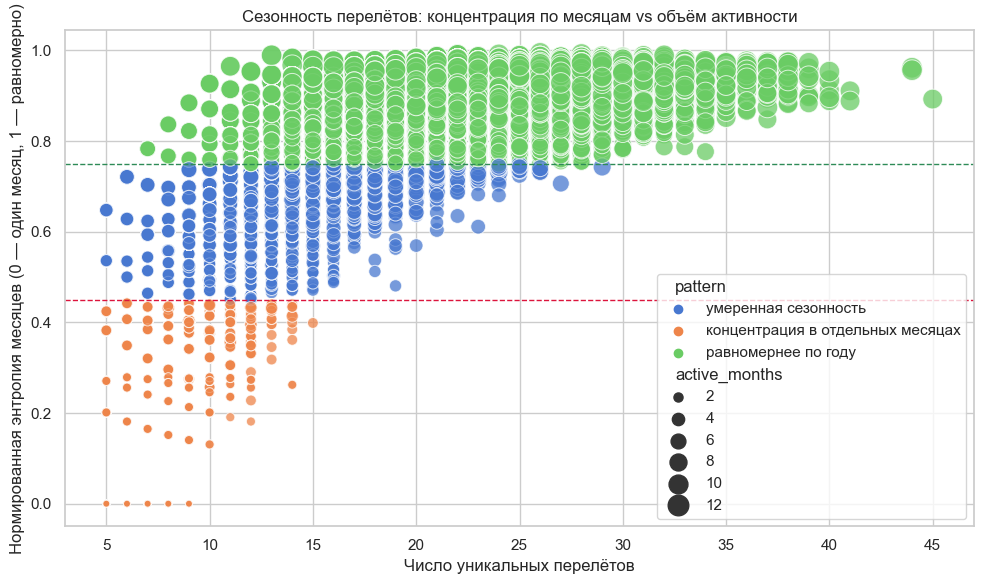

,person_key,flights,active_months,first_flight,last_flight,month_entropy,mean,std,gap_cv,pattern,unique_airports,main_airport_share,flights_geo
201237,KE 986237392,45,11,2017-01-06,2017-12-27,0.892622,8.068182,8.945306,1.108714,равномернее по году,22,0.211111,45
211258,SU 355707866,44,12,2017-01-06,2017-12-31,0.956373,8.348837,8.869111,1.062317,равномернее по году,29,0.125000,44
182807,KE 491999883,44,12,2017-01-09,2017-12-30,0.961792,8.255814,7.461307,0.903764,равномернее по году,36,0.079545,44
143896,FB 344022829,41,11,2017-01-01,2017-12-27,0.888304,9.000000,9.837135,1.093015,равномернее по году,35,0.121951,41
130848,DT 890885807,41,11,2017-01-02,2017-12-24,0.910777,8.900000,9.074619,1.019620,равномернее по году,35,0.109756,41
106031,DT 219090751,40,11,2017-01-02,2017-12-31,0.913154,9.307692,9.910531,1.064768,равномернее по году,27,0.187500,40
168170,FB 995659943,40,11,2017-02-02,2018-01-01,0.888790,8.538462,8.416294,0.985692,равномернее по году,29,0.125000,40
198511,KE 913530255,40,12,2017-01-26,2017-12-29,0.896616,8.641026,9.834117,1.138073,равномернее по году,33,0.125000,40
189232,KE 663832214,40,12,2017-01-15,2017-12-25,0.953262,8.820513,7.900272,0.895670,равномернее по году,25,0.162500,40
165162,FB 914132177,40,12,2017-01-02,2017-12-31,0.934342,9.307692,10.598296,1.138660,равномернее по году,29,0.062500,40


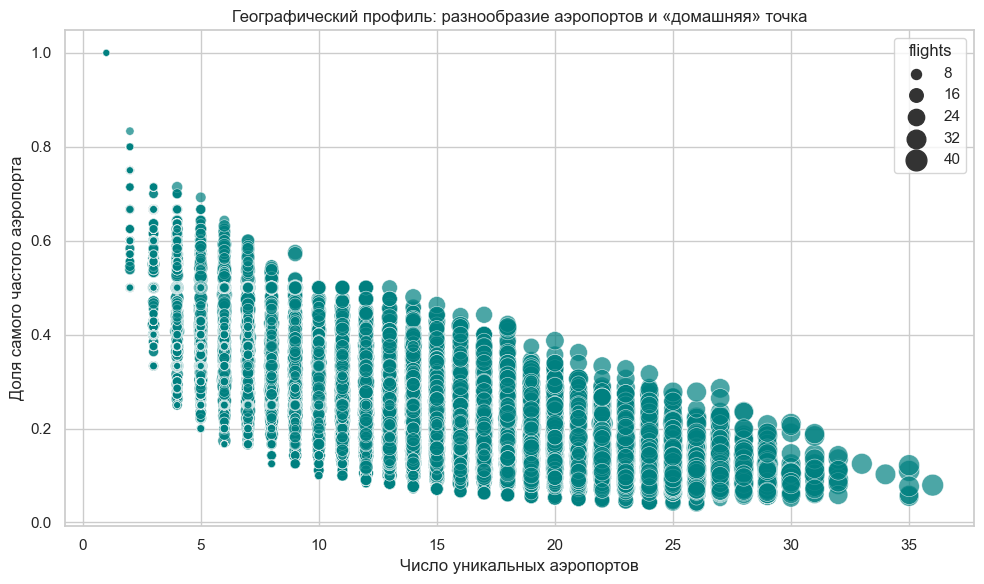

In [38]:
person_events = master[['source', 'date', 'flight', 'from_airport', 'to_airport',
                        'from_city', 'to_city',
                        'doc_number', 'ff_card']].copy()
person_events['doc_key'] = person_events['doc_number'].map(normalize_identifier)
person_events['ff_key'] = person_events['ff_card'].map(normalize_identifier)
person_events['person_key'] = person_events['doc_key'].combine_first(person_events['ff_key'])
person_events['id_type'] = np.where(person_events['doc_key'].notna(), 'Документ', 'FF-карта')
person_events = person_events.dropna(subset=['person_key', 'date']).copy()

for col in ['from_airport', 'to_airport', 'from_city', 'to_city']:
    person_events[col] = (person_events[col].astype('string').str.upper().str.strip()
                          .replace({'': pd.NA, 'NAN': pd.NA, 'NONE': pd.NA}))
person_events['year'] = person_events['date'].dt.year
person_events['month'] = person_events['date'].dt.month

event_cols = ['person_key', 'date', 'flight', 'from_airport', 'to_airport']
journeys = (person_events.sort_values(['person_key', 'date', 'source'])
           .drop_duplicates(event_cols, keep='first').reset_index(drop=True))
print(f'Событий с идентификатором: {len(person_events):,}; уникальных поездок после дедупликации: {len(journeys):,}')

# 1. стыковка перелетов
timeline = journeys.sort_values(['person_key', 'date', 'flight']).copy()
timeline['prev_to'] = timeline.groupby('person_key')['to_airport'].shift()
timeline['prev_to_city'] = timeline.groupby('person_key')['to_city'].shift()
timeline['prev_date'] = timeline.groupby('person_key')['date'].shift()
timeline['gap_days'] = (timeline['date'] - timeline['prev_date']).dt.days
timeline['airport_change_within_city'] = (timeline['prev_to_city'].eq(timeline['from_city'])
                                         & timeline['prev_to'].ne(timeline['from_airport']))
timeline['timeline_break'] = (timeline['prev_to_city'].notna() & timeline['from_city'].notna()
                              & timeline['gap_days'].gt(0)
                              & timeline['prev_to_city'].ne(timeline['from_city']))
breaks = timeline[timeline['timeline_break']].copy()
break_summary = (breaks.groupby('person_key').agg(
    breaks=('timeline_break', 'size'),
    first_date=('date', 'min'), last_date=('date', 'max'),
    examples=('flight', lambda x: ', '.join(x.astype(str).head(3)))).sort_values('breaks', ascending=False))
print(f'Несостыковок маршрута: {len(breaks):,} у {len(break_summary):,} идентификаторов.')
display(breaks[['person_key', 'prev_date', 'prev_to', 'prev_to_city', 'date', 'from_airport', 'from_city', 'to_airport', 'flight', 'gap_days']].head(30))

# 2. сезонность и регулярность
def normalized_month_entropy(months):
    p = months.value_counts(normalize=True).values
    return -(p * np.log(p)).sum() / np.log(12) if len(p) else np.nan

seasonality = journeys.groupby('person_key').agg(
    flights=('date', 'size'), active_months=('month', 'nunique'),
    first_flight=('date', 'min'), last_flight=('date', 'max')).reset_index()
seasonality['month_entropy'] = journeys.groupby('person_key')['month'].apply(normalized_month_entropy).values
gaps = journeys.sort_values(['person_key', 'date']).groupby('person_key')['date'].diff().dt.days
gap_stats = gaps.groupby(journeys.sort_values(['person_key', 'date'])['person_key']).agg(['mean', 'std'])
seasonality = seasonality.join(gap_stats, on='person_key')
seasonality['gap_cv'] = seasonality['std'] / seasonality['mean']
seasonality['pattern'] = np.select(
    [seasonality['month_entropy'].lt(.45), seasonality['month_entropy'].ge(.75)],
    ['концентрация в отдельных месяцах', 'равномернее по году'], default='умеренная сезонность')

plot_seasonality = seasonality.query('flights >= 5').copy()
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=plot_seasonality, x='flights', y='month_entropy', hue='pattern',
                size='active_months', sizes=(25, 220), alpha=.75, ax=ax)
ax.axhline(.45, color='crimson', ls='--', lw=1)
ax.axhline(.75, color='seagreen', ls='--', lw=1)
ax.set_title('Сезонность перелётов: концентрация по месяцам vs объём активности')
ax.set_xlabel('Число уникальных перелётов')
ax.set_ylabel('Нормированная энтропия месяцев (0 — один месяц, 1 — равномерно)')
plt.tight_layout()
plt.show()

# 3. география пассажира
airports = pd.concat([
    journeys[['person_key', 'from_airport']].rename(columns={'from_airport': 'airport'}),
    journeys[['person_key', 'to_airport']].rename(columns={'to_airport': 'airport'})
]).dropna()
geo = airports.groupby('person_key').agg(
    unique_airports=('airport', 'nunique'),
    main_airport_share=('airport', lambda x: x.value_counts(normalize=True).iloc[0]))
geo = geo.join(seasonality.set_index('person_key')['flights'])
display(seasonality.join(geo, on='person_key', rsuffix='_geo').sort_values('flights', ascending=False).head(30))

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=geo.query('flights >= 3'), x='unique_airports', y='main_airport_share',
                size='flights', sizes=(25, 250), alpha=.7, color='teal', ax=ax)
ax.set_title('Географический профиль: разнообразие аэропортов и «домашняя» точка')
ax.set_xlabel('Число уникальных аэропортов')
ax.set_ylabel('Доля самого частого аэропорта')
plt.tight_layout()
plt.show()

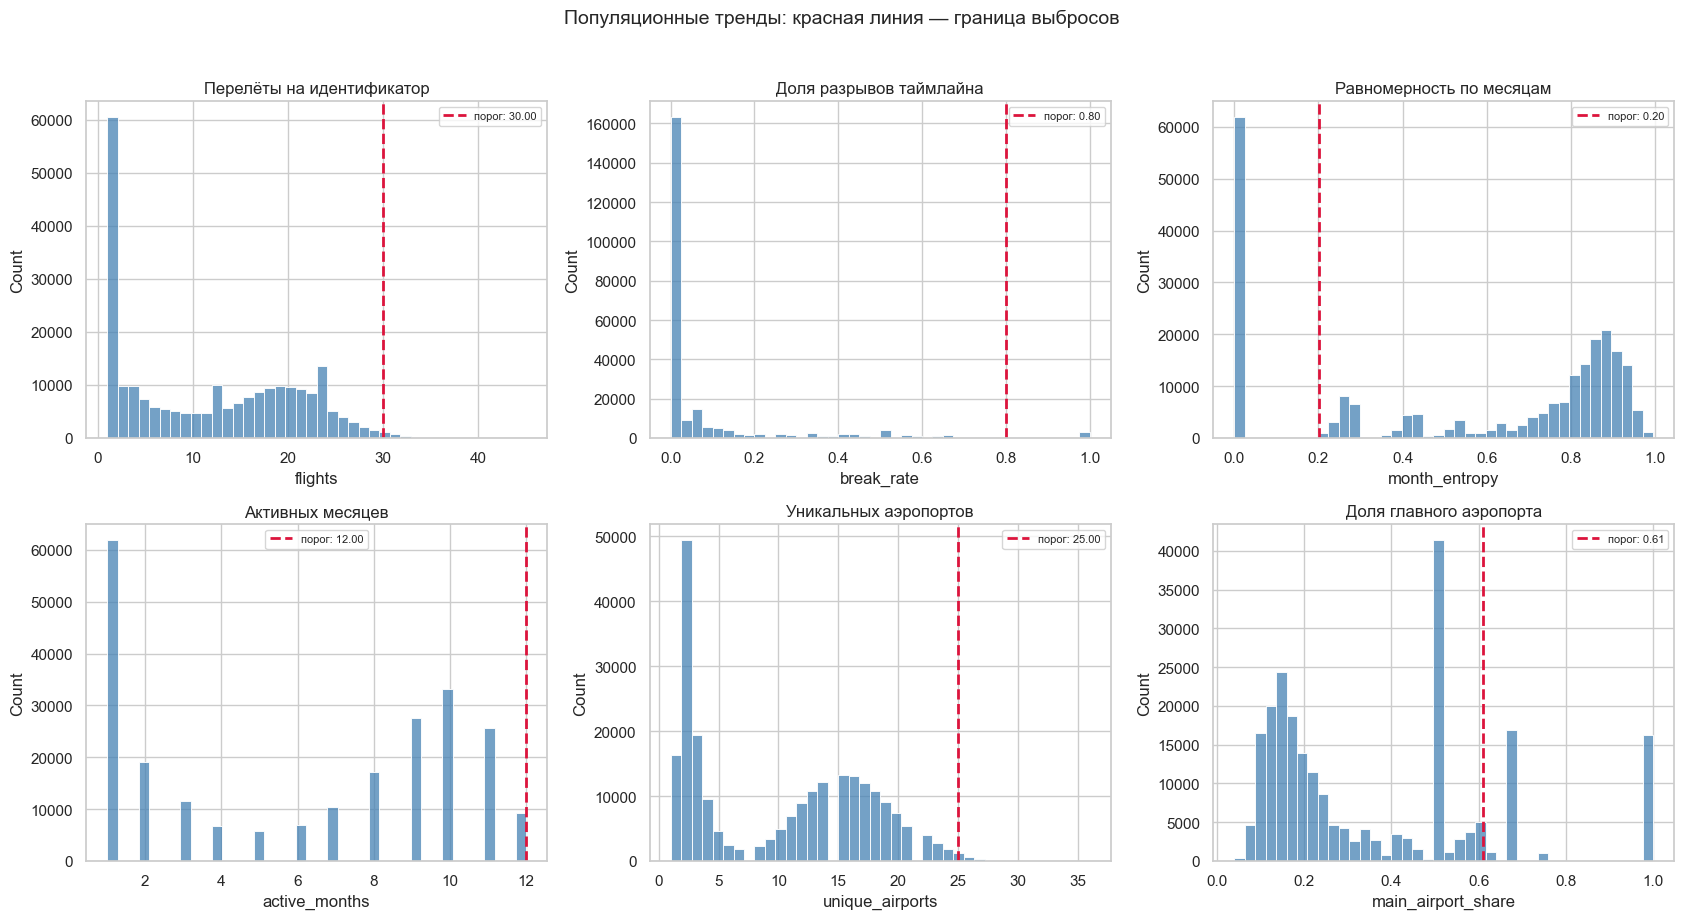

,person_key,trend_outlier_score,triggered_rules,flights,timeline_breaks,break_rate,month_entropy,active_months,unique_airports,main_airport_share,sources
0,FB 139888197,3,"volume, month_coverage, geography",39,21,0.552632,0.960438,12,30,0.102564,1
1,DT 728140633,3,"volume, month_coverage, geography",34,12,0.387097,0.956686,12,29,0.117647,2
2,DT 127831315,3,"volume, month_coverage, geography",36,11,0.314286,0.933619,12,31,0.125000,2
3,SU 479325967,3,"volume, month_coverage, geography",31,10,0.333333,0.962361,12,26,0.129032,2
4,FB 419866303,3,"volume, month_coverage, geography",32,9,0.3,0.953382,12,27,0.187500,2
5,KE 880565562,3,"volume, month_coverage, geography",32,9,0.3,0.929367,12,29,0.125000,2
6,DT 93001894,3,"volume, month_coverage, geography",30,9,0.321429,0.953776,12,30,0.100000,2
7,DT 79732294,3,"volume, month_coverage, geography",32,8,0.285714,0.940221,12,26,0.093750,2
8,FB 908838533,3,"volume, month_coverage, geography",32,8,0.275862,0.954252,12,26,0.140625,2
9,KE 351501780,3,"volume, month_coverage, geography",30,8,0.275862,0.960795,12,26,0.100000,2


In [39]:
# тренды и выбросы
valid_pairs = timeline[timeline['prev_to_city'].notna() & timeline['from_city'].notna() & timeline['gap_days'].gt(0)]
break_rate = valid_pairs.groupby('person_key')['timeline_break'].agg(['sum', 'count']).rename(
    columns={'sum': 'timeline_breaks', 'count': 'comparable_transitions'})
break_rate['break_rate'] = break_rate['timeline_breaks'] / break_rate['comparable_transitions']
source_coverage = journeys.groupby('person_key')['source'].nunique().rename('sources')
population = (seasonality.set_index('person_key')[['flights', 'active_months', 'month_entropy']]
              .join(geo[['unique_airports', 'main_airport_share']])
              .join(break_rate).join(source_coverage)
              .fillna({'timeline_breaks': 0, 'comparable_transitions': 0, 'break_rate': 0}))

eligible_seasonality = population.query('flights >= 5')['month_entropy']
thresholds = {
    'flights_hi': population['flights'].quantile(.99),
    'break_rate_hi': population.loc[population['comparable_transitions'] >= 3, 'break_rate'].quantile(.99),
    'entropy_lo': eligible_seasonality.quantile(.01),
    'active_months_hi': population['active_months'].quantile(.99),
    'airports_hi': population['unique_airports'].quantile(.99),
    'home_share_hi': population.loc[population['flights'] >= 5, 'main_airport_share'].quantile(.99),
}
population['flag_volume'] = population['flights'].ge(thresholds['flights_hi'])
population['flag_timeline'] = ((population['comparable_transitions'] >= 3) &
                               population['break_rate'].ge(thresholds['break_rate_hi']))
population['flag_seasonality'] = ((population['flights'] >= 5) &
                                  population['month_entropy'].le(thresholds['entropy_lo']))
population['flag_month_coverage'] = population['active_months'].ge(thresholds['active_months_hi'])
population['flag_geography'] = population['unique_airports'].ge(thresholds['airports_hi'])
population['flag_home_airport'] = ((population['flights'] >= 5) &
                                   population['main_airport_share'].ge(thresholds['home_share_hi']))
flag_columns = [col for col in population if col.startswith('flag_')]
population['trend_outlier_score'] = population[flag_columns].sum(axis=1)

plots = [
    ('flights', thresholds['flights_hi'], 'Перелёты на идентификатор'),
    ('break_rate', thresholds['break_rate_hi'], 'Доля разрывов таймлайна'),
    ('month_entropy', thresholds['entropy_lo'], 'Равномерность по месяцам'),
    ('active_months', thresholds['active_months_hi'], 'Активных месяцев'),
    ('unique_airports', thresholds['airports_hi'], 'Уникальных аэропортов'),
    ('main_airport_share', thresholds['home_share_hi'], 'Доля главного аэропорта'),
]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (metric, threshold, title) in zip(axes.flat, plots):
    sns.histplot(population[metric].dropna(), bins=40, color='steelblue', ax=ax)
    ax.axvline(threshold, color='crimson', ls='--', lw=2, label=f'порог: {threshold:.2f}')
    ax.set_title(title)
    ax.legend(fontsize=8)
fig.suptitle('Популяционные тренды: красная линия — граница выбросов', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

trend_candidates = population.query('trend_outlier_score >= 2').sort_values(
    ['trend_outlier_score', 'timeline_breaks', 'flights'], ascending=False).reset_index()
trend_candidates['triggered_rules'] = trend_candidates[flag_columns].apply(
    lambda row: ', '.join(col.replace('flag_', '') for col, value in row.items() if value), axis=1)
display(trend_candidates[['person_key', 'trend_outlier_score', 'triggered_rules', 'flights',
                          'timeline_breaks', 'break_rate', 'month_entropy', 'active_months',
                          'unique_airports', 'main_airport_share', 'sources']].head(50))


## 11. Подозрительные личности

In [40]:
export_path = BASE / 'master_dataset.parquet'
tmp_path = BASE / 'master_dataset.tmp.parquet'
writer = None
object_columns = master.select_dtypes(include='object').columns.tolist()
try:
    for start in range(0, len(master), 50_000):
        chunk = master.iloc[start:start + 50_000].copy()
        chunk[object_columns] = chunk[object_columns].astype('string')
        table = pa.Table.from_pandas(chunk, preserve_index=False)
        if writer is None:
            writer = pq.ParquetWriter(tmp_path, table.schema, compression='snappy')
        writer.write_table(table)
finally:
    if writer is not None:
        writer.close()
if writer is not None:
    tmp_path.replace(export_path)

analysis_columns = ['entity_id', 'source', 'date', 'flight', 'from_airport', 'to_airport',
                    'from_city', 'to_city', 'doc_number', 'booking_code',
                    'ticket_number', 'ff_card', 'full_name_key']
del master, boarding, sirena, bp, ff_df, xml_df, sky_df
del b_unified, s_unified, st_unified, px_unified, ff_unified, bp_unified
gc.collect()
graph_events = pd.read_parquet(export_path, columns=analysis_columns).dropna(subset=['entity_id', 'date'])
for col in ['from_airport', 'to_airport', 'from_city', 'to_city']:
    graph_events[col] = (graph_events[col].astype('string').str.upper().str.strip()
                         .replace({'': pd.NA, 'NAN': pd.NA, 'NONE': pd.NA}))

dedup_cols = ['entity_id', 'date', 'flight', 'from_airport', 'to_airport']
entity_journeys = (graph_events.sort_values(['entity_id', 'date', 'source'])
                   .drop_duplicates(dedup_cols, keep='first').reset_index(drop=True))

timeline_v2 = entity_journeys[['entity_id', 'date', 'flight', 'from_city', 'to_city', 'source']].sort_values(['entity_id', 'date', 'flight']).copy()
timeline_v2['prev_to_city'] = timeline_v2.groupby('entity_id')['to_city'].shift()
timeline_v2['prev_date'] = timeline_v2.groupby('entity_id')['date'].shift()
timeline_v2['gap_days'] = (timeline_v2['date'] - timeline_v2['prev_date']).dt.days

# интервал > 7 дней не трактуется как разрыв
timeline_v2['short_gap_route_break'] = (
    timeline_v2['prev_to_city'].notna() & timeline_v2['from_city'].notna()
    & timeline_v2['gap_days'].between(1, 7)
    & timeline_v2['prev_to_city'].ne(timeline_v2['from_city'])
)
short_breaks = timeline_v2[timeline_v2['short_gap_route_break']].copy()
print(f'Уникальных поездок: {len(entity_journeys):,}')
print(f'Коротких разрывов: {len(short_breaks):,} у {short_breaks["entity_id"].nunique():,} сущностей.')


Уникальных поездок: 2,778,299
Коротких разрывов: 29,234 у 23,566 сущностей.


In [41]:
# минимум два независимых сигнала
entity_stats = entity_journeys.groupby('entity_id').agg(
    flights=('date', 'size'), active_months=('date', lambda x: x.dt.month.nunique()),
    airports=('from_airport', 'nunique'), first_date=('date', 'min'), last_date=('date', 'max'))
source_stats = graph_events.groupby('entity_id')['source'].nunique().rename('sources')
doc_stats = graph_events.assign(has_doc=graph_events['doc_number'].notna()).groupby('entity_id')['has_doc'].any()
ff_stats = graph_events.assign(has_ff=graph_events['ff_card'].notna()).groupby('entity_id')['has_ff'].any()
break_stats = short_breaks.groupby('entity_id').size().rename('short_breaks')
entity_stats = entity_stats.join([source_stats, doc_stats.rename('has_document'), ff_stats.rename('has_ff_card'), break_stats]).fillna({'short_breaks': 0})
eligible = entity_stats.query('flights >= 5')
thresholds_v2 = {
    'flights_p995': eligible['flights'].quantile(.995),
    'airports_p99': eligible['airports'].quantile(.99),
    'short_breaks_p99': entity_stats.loc[entity_stats['flights'] >= 3, 'short_breaks'].quantile(.99),
}
entity_stats['flag_extreme_volume'] = entity_stats['flights'].ge(thresholds_v2['flights_p995'])
entity_stats['flag_extreme_geography'] = entity_stats['airports'].ge(thresholds_v2['airports_p99'])
entity_stats['flag_repeated_short_breaks'] = entity_stats['short_breaks'].ge(max(2, thresholds_v2['short_breaks_p99']))
entity_stats['cross_source_evidence'] = entity_stats['sources'].ge(2)
entity_stats['strong_id_evidence'] = entity_stats['has_document'] & entity_stats['has_ff_card']
risk_flags = ['flag_extreme_volume', 'flag_extreme_geography', 'flag_repeated_short_breaks']
entity_stats['risk_signals'] = entity_stats[risk_flags].sum(axis=1)
entity_stats['evidence_signals'] = entity_stats[['cross_source_evidence', 'strong_id_evidence']].sum(axis=1)
case_queue = entity_stats[(entity_stats['risk_signals'] >= 2) | ((entity_stats['flag_repeated_short_breaks']) & (entity_stats['evidence_signals'] >= 1))].copy()
case_queue['triggered_rules'] = case_queue[risk_flags].apply(lambda r: ', '.join(k.replace('flag_', '') for k, v in r.items() if v), axis=1)
case_queue = case_queue.sort_values(['risk_signals', 'evidence_signals', 'short_breaks', 'flights'], ascending=False).reset_index()
print('Пороги:', thresholds_v2)
display(case_queue.head(50))

Пороги: {'flights_p995': 34.0, 'airports_p99': 24.0, 'short_breaks_p99': 2.0}


,entity_id,flights,active_months,airports,first_date,last_date,sources,has_document,has_ff_card,short_breaks,flag_extreme_volume,flag_extreme_geography,flag_repeated_short_breaks,cross_source_evidence,strong_id_evidence,risk_signals,evidence_signals,triggered_rules
0,entity_14122,44,11,24,2017-01-02,2017-12-24,4,True,True,5.0,True,True,True,True,True,3,2,"extreme_volume, extreme_geography, r..."
1,entity_49219,34,12,25,2017-01-15,2017-12-18,4,True,True,5.0,True,True,True,True,True,3,2,"extreme_volume, extreme_geography, r..."
2,entity_50933,37,12,25,2017-01-01,2017-12-16,4,True,True,3.0,True,True,True,True,True,3,2,"extreme_volume, extreme_geography, r..."
3,entity_68676,37,12,27,2017-01-01,2017-12-07,5,True,True,3.0,True,True,True,True,True,3,2,"extreme_volume, extreme_geography, r..."
4,entity_151308,36,12,29,2017-01-19,2017-12-26,4,True,True,3.0,True,True,True,True,True,3,2,"extreme_volume, extreme_geography, r..."
5,entity_62750,36,12,24,2017-01-11,2017-12-26,4,True,True,3.0,True,True,True,True,True,3,2,"extreme_volume, extreme_geography, r..."
6,entity_120970,35,11,24,2017-01-04,2017-12-24,4,True,True,3.0,True,True,True,True,True,3,2,"extreme_volume, extreme_geography, r..."
7,entity_193986,35,11,27,2017-01-08,2018-01-01,3,True,True,3.0,True,True,True,True,True,3,2,"extreme_volume, extreme_geography, r..."
8,entity_238532,35,12,27,2017-01-09,2017-12-29,4,True,True,3.0,True,True,True,True,True,3,2,"extreme_volume, extreme_geography, r..."
9,entity_82867,35,11,27,2017-01-02,2017-12-27,5,True,True,3.0,True,True,True,True,True,3,2,"extreme_volume, extreme_geography, r..."


In [42]:
# топ подозрительных личностей
top_case_ids = set(case_queue['entity_id'].head(50))
case_events = (graph_events[graph_events['entity_id'].isin(top_case_ids)]
    .sort_values(['entity_id', 'date', 'source'])
    [['entity_id', 'source', 'date', 'flight', 'from_airport', 'to_airport', 'doc_number', 'booking_code', 'ticket_number', 'ff_card', 'full_name_key']])
case_breaks = (short_breaks[short_breaks['entity_id'].isin(top_case_ids)]
    [['entity_id', 'prev_date', 'prev_to_city', 'date', 'from_city', 'to_city', 'flight', 'gap_days', 'source']]
    .sort_values(['entity_id', 'date']))
case_queue.to_csv(BASE / 'automated_case_queue.csv', index=False)
case_events.to_csv(BASE / 'automated_case_events.csv', index=False)
case_breaks.to_csv(BASE / 'automated_case_route_breaks.csv', index=False)

## 12. Контроль достоверности маршрутов

In [43]:
# согласованность маршрутов по FF-карте, дате и номеру рейса
route_audit = graph_events.dropna(subset=['ff_card', 'date', 'flight', 'from_airport', 'to_airport']).copy()
route_audit['ff_key'] = route_audit['ff_card'].map(normalize_identifier)
route_audit['route'] = route_audit['from_airport'].astype(str) + '→' + route_audit['to_airport'].astype(str)
route_audit = route_audit.dropna(subset=['ff_key'])

by_source = (route_audit.groupby(['ff_key', 'date', 'flight', 'source'])['route']
             .agg(lambda x: x.mode().iat[0] if len(x.mode()) == 1 else pd.NA)
             .reset_index())
group_cols = ['ff_key', 'date', 'flight']
def strict_mode(values):
    counts = values.value_counts()
    return counts.index[0] if len(counts) and (len(counts) == 1 or counts.iloc[0] > counts.iloc[1]) else pd.NA
consensus = by_source.groupby(group_cols)['route'].agg(strict_mode).rename('consensus_route').reset_index()
by_source = by_source.merge(consensus, on=group_cols, how='left')
by_source['comparable'] = by_source['consensus_route'].notna()

route_left = by_source['route'].astype('string').fillna('__MISSING_ROUTE__').to_numpy()
route_right = by_source['consensus_route'].astype('string').fillna('__MISSING_ROUTE__').to_numpy()
by_source['route_disagrees'] = (by_source['comparable'].to_numpy(dtype=bool) &
                                np.not_equal(route_left, route_right))
source_route_quality = by_source.groupby('source').agg(
    comparable=('comparable', 'sum'), disagreements=('route_disagrees', 'sum')
)
source_route_quality['disagreement_rate'] = source_route_quality['disagreements'] / source_route_quality['comparable'].replace(0, np.nan)
source_route_quality['trusted_for_timeline'] = source_route_quality['disagreement_rate'].fillna(0).le(.05)
display(source_route_quality.sort_values('disagreement_rate', ascending=False))
source_route_quality.to_csv(BASE / 'route_source_quality.csv')

trusted_sources = source_route_quality.index[source_route_quality['trusted_for_timeline']]
timeline_events = graph_events[graph_events['source'].isin(trusted_sources)].copy()
timeline_journeys = (timeline_events.sort_values(['entity_id', 'date', 'source'])
    .drop_duplicates(['entity_id', 'date', 'flight', 'from_airport', 'to_airport'], keep='first'))
timeline_clean = timeline_journeys.sort_values(['entity_id', 'date', 'flight']).copy()
timeline_clean['prev_to_city'] = timeline_clean.groupby('entity_id')['to_city'].shift()
timeline_clean['prev_date'] = timeline_clean.groupby('entity_id')['date'].shift()
timeline_clean['gap_days'] = (timeline_clean['date'] - timeline_clean['prev_date']).dt.days
timeline_clean['short_gap_route_break'] = ((
    timeline_clean['prev_to_city'].notna() & timeline_clean['from_city'].notna()
    & timeline_clean['gap_days'].between(1, 7)
    & timeline_clean['prev_to_city'].ne(timeline_clean['from_city']).fillna(False)
).fillna(False).astype(bool))
clean_breaks = timeline_clean[timeline_clean['short_gap_route_break']].copy()

clean_breaks['break_severity'] = 1 / clean_breaks['gap_days'].astype(float)
print(f'Коротких разрывов после контроля качества: {len(clean_breaks):,} (было {len(short_breaks):,}).')


,comparable,disagreements,disagreement_rate,trusted_for_timeline
source,,,,
SkyTeam,1631496,7700,0.00472,True
FF_Forum,1698370,0,0.00000,True
Pointz,429275,0,0.00000,True
Sirena,51917,0,0.00000,True


Коротких разрывов после контроля качества: 29,893 (было 29,234).


In [49]:
clean_break_stats = clean_breaks.groupby('entity_id').size().rename('trusted_short_breaks')
break_severity = clean_breaks.groupby('entity_id')['break_severity'].sum().rename('trusted_break_severity')
final_cases = entity_stats.join([clean_break_stats, break_severity]).fillna(
    {'trusted_short_breaks': 0, 'trusted_break_severity': 0}).copy()
severity_threshold = final_cases.loc[final_cases['flights'] >= 3, 'trusted_break_severity'].quantile(.99)
final_cases['flag_severe_trusted_breaks'] = final_cases['trusted_break_severity'].ge(severity_threshold)
final_cases['final_risk_signals'] = (final_cases['flag_extreme_volume'].astype(int)
    + final_cases['flag_extreme_geography'].astype(int)
    + final_cases['flag_severe_trusted_breaks'].astype(int))
final_cases = final_cases[(final_cases['final_risk_signals'] >= 2) |
    (final_cases['flag_severe_trusted_breaks'] & final_cases['evidence_signals'].ge(1))].copy()
final_cases['triggered_rules'] = final_cases.apply(lambda r: ', '.join(name for name, value in {
    'extreme_volume': r['flag_extreme_volume'], 'extreme_geography': r['flag_extreme_geography'],
    'severe_trusted_breaks': r['flag_severe_trusted_breaks']}.items() if value), axis=1)
final_cases = final_cases.sort_values(['final_risk_signals','evidence_signals','trusted_break_severity','flights'], ascending=False).reset_index()
final_cases.to_csv(BASE / 'final_case_queue.csv', index=False)
clean_breaks[clean_breaks['entity_id'].isin(final_cases['entity_id'].head(50))].to_csv(
    BASE / 'final_case_route_breaks.csv', index=False)
print(f'Порог разрывов: {severity_threshold:.3f}; итоговых кейсов: {len(final_cases):,}.')
display(final_cases.head(50))

Порог разрывов: 1.143; итоговых кейсов: 1,849.


,entity_id,flights,active_months,airports,first_date,last_date,sources,has_document,has_ff_card,short_breaks,flag_extreme_volume,flag_extreme_geography,flag_repeated_short_breaks,cross_source_evidence,strong_id_evidence,risk_signals,evidence_signals,trusted_short_breaks,trusted_break_severity,flag_severe_trusted_breaks,final_risk_signals,triggered_rules
0,entity_49219,34,12,25,2017-01-15,2017-12-18,4,True,True,5.0,True,True,True,True,True,3,2,5.0,2.500000,True,3,"extreme_volume, extreme_geography, s..."
1,entity_14122,44,11,24,2017-01-02,2017-12-24,4,True,True,5.0,True,True,True,True,True,3,2,5.0,2.142857,True,3,"extreme_volume, extreme_geography, s..."
2,entity_82867,35,11,27,2017-01-02,2017-12-27,5,True,True,3.0,True,True,True,True,True,3,2,3.0,2.142857,True,3,"extreme_volume, extreme_geography, s..."
3,entity_108035,36,11,25,2017-01-02,2017-12-25,4,True,True,2.0,True,True,True,True,True,3,2,2.0,2.000000,True,3,"extreme_volume, extreme_geography, s..."
4,entity_71711,40,12,24,2017-01-01,2017-12-13,4,True,True,2.0,True,True,True,True,True,3,2,3.0,1.750000,True,3,"extreme_volume, extreme_geography, s..."
5,entity_32930,34,11,27,2017-01-25,2017-12-28,5,True,True,3.0,True,True,True,True,True,3,2,3.0,1.700000,True,3,"extreme_volume, extreme_geography, s..."
6,entity_120970,35,11,24,2017-01-04,2017-12-24,4,True,True,3.0,True,True,True,True,True,3,2,3.0,1.642857,True,3,"extreme_volume, extreme_geography, s..."
7,entity_22040,37,11,24,2017-01-08,2017-11-06,4,True,True,2.0,True,True,True,True,True,3,2,2.0,1.500000,True,3,"extreme_volume, extreme_geography, s..."
8,entity_41004,35,11,24,2017-01-01,2017-12-31,4,True,True,2.0,True,True,True,True,True,3,2,2.0,1.500000,True,3,"extreme_volume, extreme_geography, s..."
9,entity_95336,35,12,27,2017-01-04,2017-12-26,5,True,True,2.0,True,True,True,True,True,3,2,3.0,1.416667,True,3,"extreme_volume, extreme_geography, s..."


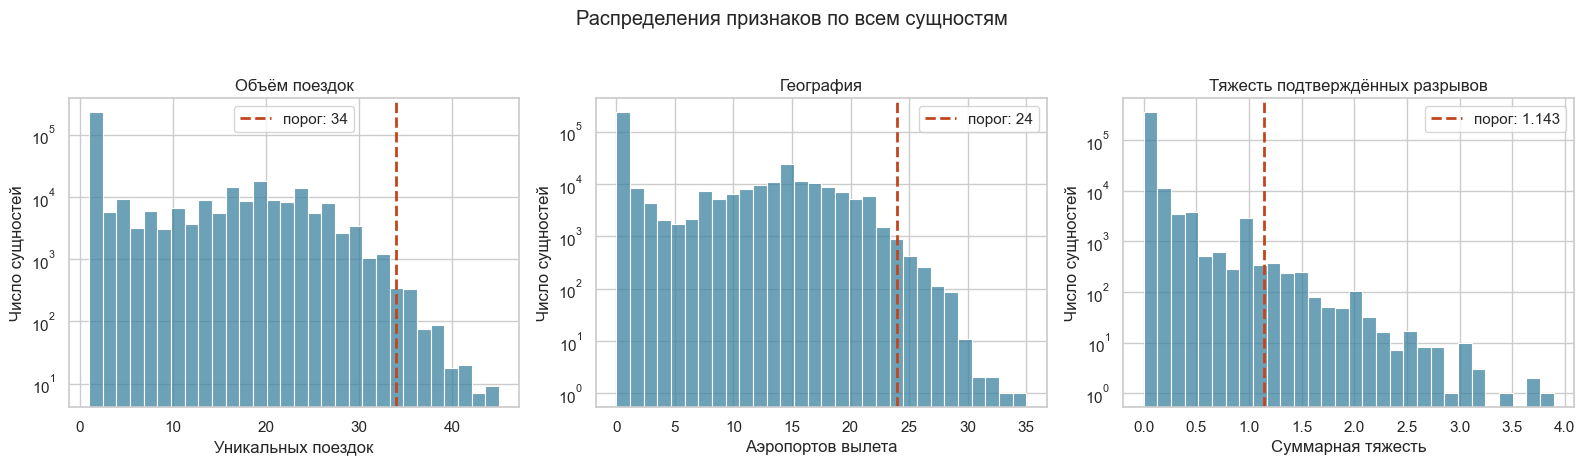

In [47]:
all_entities = entity_stats.join([clean_break_stats, break_severity]).fillna(
    {'trusted_short_breaks': 0, 'trusted_break_severity': 0}
)

plot_specs = [
    ('flights', thresholds_v2['flights_p995'], 'Объём поездок', 'Уникальных поездок'),
    ('airports', thresholds_v2['airports_p99'], 'География', 'Аэропортов вылета'),
    ('trusted_break_severity', severity_threshold, 'Тяжесть подтверждённых разрывов', 'Суммарная тяжесть'),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (column, threshold, title, xlabel) in zip(axes, plot_specs):
    sns.histplot(all_entities[column].dropna(), bins=30, color='#3B82A0', ax=ax)
    label = f'порог: {threshold:.3f}' if column == 'trusted_break_severity' else f'порог: {threshold:.0f}'
    ax.axvline(threshold, color='#C2451E', linestyle='--', linewidth=2, label=label)
    ax.set_title(title)
    ax.set_yscale('log')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Число сущностей')
    ax.legend()

fig.suptitle('Распределения признаков по всем сущностям', y=1.03)
plt.tight_layout()
plt.show()